# Task 1 — Individual, tuned and hybrid recommenders

**DSAIT4335 Recommender Systems — final project**

| Task | What this notebook builds |
|---|---|
| **1.1** | Individual recommendation models under one frozen evaluation protocol (all class models, content-based excluded, plus the `Random` and `Pop` baselines) |
| **1.2** | Hyper-parameter tuning of every individual model, selected on the **validation** split only |
| **1.3** | A **weighted hybrid** whose coefficients are **learned by a regression model** on the validation split |

**Setting.** MovieLens-100K, *ranking* task (not rating prediction), full-ranking evaluation, `topk = 10`, implemented with the course RecBole fork (`Project/RecBole_DSAIT4335`, version 1.2.1) on CPU.

**How to use this notebook.** Run it top to bottom. Every expensive stage is cached under `Project/runs/`, so a second execution only recomputes what is missing. Set `FORCE = True` (cell §1.2) to recompute everything, or `FAST_SMOKE = True` for a ~3-minute end-to-end smoke test with 2 epochs and one tuning configuration per model.

**Artefacts written**

| Path (under `Project/runs/`) | Content |
|---|---|
| `splits/` | train/valid/test interactions with the original user/item ids |
| `results/baseline.json` | Task 1.1 training records (params, valid + RecBole test metrics, checkpoint) |
| `tuning/<model>.csv` | Task 1.2 grid-search results, one row per configuration |
| `tables/table_1_1.csv`, `table_1_2.csv`, `table_1_3.csv` | report-ready result tables |
| `lists/<run_id>_top10.json` | top-10 recommendations per user (external ids) |
| `scores/<run_id>.npz` | dense item score matrices (validation + test) for the hybrid |
| `hybrids/weights.csv`, `hybrids/lists_*.json` | Task 1.3 learned coefficients and hybrid recommendations |
| `checkpoints/<run_id>/` | RecBole checkpoints |

> Content-based recommenders are **excluded** from Task 1.1 (project brief, slide 5). `Random` and `Pop` are included because Task 2.2 requires them as naïve baselines.


## How to run this notebook

1. **Select the project environment.** Use the kernel `Python 3 (Project venv)`. A project-local kernel spec already exists at `Project/.jupyter/kernels/recsys`, so start Jupyter with that directory on the kernel path:
   ```bash
   JUPYTER_PATH=$PWD/.jupyter .venv/bin/jupyter lab      # from Project/
   ```
   If you prefer to launch Jupyter normally, register the kernel once instead (any Python 3.12 interpreter that can `import recbole` works — `Project/.venv/bin/python` is the one this notebook was developed against):
   ```bash
   .venv/bin/python -m ipykernel install --user --name recsys --display-name "Python 3 (Project venv)"
   ```
2. **Run all cells top to bottom.** Nothing else is required: the split, the models and the hybrid are all built here from `Project/RecBole_DSAIT4335/dataset/ml-100k`.

| Stage | What happens | Typical runtime (CPU, 12 cores, `N_JOBS = 3`) |
|---|---|---|
| §1 Task 1.1 | 11 individual models on the full dataset + top-10 and score exports | ~5–8 min |
| §2 Task 1.2 | ~80 tuning configurations selected on validation, then the winners exported | ~20–35 min |
| §3 Task 1.3 | coefficients learned on the validation split, hybrids evaluated on test | < 1 min |

3. **Interrupting is safe.** Every stage is cached under `Project/runs/`: re-running the notebook skips whatever already exists and continues where it stopped. Delete `Project/runs/` to start from scratch, or set `FORCE = True` in §1.2 to recompute everything. `FAST_SMOKE = True` runs the whole notebook with 2 epochs and one configuration per model in ~3 minutes — useful to check the environment before the real run.
4. **Where the results are.** Each task prints its table inline and writes it to `Project/runs/tables/table_1_*.csv`; the figures are written to `Project/runs/tables/fig_*.png`. The trained model artefacts are the usual RecBole checkpoints under `Project/runs/checkpoints/<run_id>/`, and RecBole's per-run training logs go to `Project/RecBole_DSAIT4335/log/<Model>/`.
5. **Knobs.** `N_JOBS` (parallel training jobs), `HYBRID_BASE` (which models feed the hybrid), `TUNING_GRIDS` (the searched configurations) and `K`/`topk` are all defined in §1.2–§2.0 and are safe to edit; `K = 10` is used consistently by RecBole and by our own metrics.


In [1]:
# =============================================================================
# §1.1  Environment, imports and paths
# =============================================================================
import os
import sys
import json
import time
import logging
import warnings
import itertools
from pathlib import Path

# --- locate the project directory (works from Project/ and from the repo root)
_here = Path.cwd().resolve()
PROJECT = next(p for p in (_here, *_here.parents) if (p / "RecBole_DSAIT4335").is_dir())
REPO = PROJECT / "RecBole_DSAIT4335"
RUNS = PROJECT / "runs"

for _sub in ("results", "tuning", "scores", "lists", "checkpoints", "tables", "hybrids", "splits"):
    (RUNS / _sub).mkdir(parents=True, exist_ok=True)

# Matplotlib/Jupyter need writable config directories; HOME may be read-only here.
os.environ.setdefault("MPLCONFIGDIR", str(RUNS / ".mplconfig"))

import numpy as np
import pandas as pd
import matplotlib

# In a notebook kernel keep the kernel's backend so figures render inline; when executed
# headlessly (e.g. nbconvert --execute) fall back to Agg so no display is required.
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
from joblib import Parallel, delayed

sys.path.insert(0, str(REPO))
from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.quick_start import run_recbole, load_data_and_model
from recbole.utils import init_seed, init_logger, get_model, get_trainer
from recbole.utils.case_study import full_sort_scores, full_sort_topk
import recbole

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# RecBole 1.2.1 calls np.float_, removed in NumPy 2 — fail early instead of deep inside RecBole.
assert np.__version__.startswith("1."), "RecBole 1.2.1 requires NumPy < 2"
assert sys.version_info[:2] == (3, 12), "this environment is pinned to Python 3.12"

print("python     :", sys.version.split()[0], "|", sys.executable)
print("recbole    :", recbole.__version__)
print("torch      :", torch.__version__, "| cuda available:", torch.cuda.is_available())
print("numpy      :", np.__version__, "| pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__)
print("project    :", PROJECT)
print("artefacts  :", RUNS)


C:\Users\Sanjay Sathish\Desktop\TU Delft\Q5\Recommender Systems\Project\RecommenderSystems\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-22 17:13:33,368	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-22 17:13:34,385	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


python     : 3.12.8 | C:\Users\Sanjay Sathish\Desktop\TU Delft\Q5\Recommender Systems\Project\RecommenderSystems\.venv\Scripts\python.exe
recbole    : 1.2.1
torch      : 2.14.1+cpu | cuda available: False
numpy      : 1.26.4 | pandas: 2.3.3 | matplotlib: 3.11.2
project    : C:\Users\Sanjay Sathish\Desktop\TU Delft\Q5\Recommender Systems\Project\RecommenderSystems
artefacts  : C:\Users\Sanjay Sathish\Desktop\TU Delft\Q5\Recommender Systems\Project\RecommenderSystems\runs


### Environment used for these runs

| Component | Version | Note |
|---|---|---|
| Python | 3.12.13 | RecBole 1.2.1 calls `np.float_`, removed in NumPy 2, and NumPy < 2 has no Python 3.13 wheels — hence the pin |
| RecBole | 1.2.1 (course fork, editable install) | `Project/RecBole_DSAIT4335` |
| NumPy / pandas | 1.26.4 / 2.3.3 | must stay `numpy<2`, `pandas<3` |
| torch | 2.14.1+cpu | every run in this notebook is CPU-only |
| scikit-learn / scipy / joblib | 1.9.1 / 1.17.1 / 1.6.0 | coefficient learning and parallel training |
| matplotlib | 3.11.2 | figures (`runs/tables/fig_*.png`) |

Provisioning from `Project/`:

```bash
uv add ipykernel nbclient nbformat pyyaml "ray[tune]" "numpy<2" "pandas<3" lightgbm xgboost matplotlib scikit-learn
uv pip install -e ./RecBole_DSAIT4335     # re-run after ANY uv add/sync — uv prunes the editable install
```

Two traps worth knowing: `uv add matplotlib` can pull NumPy 2 back in (re-pin afterwards with `uv pip install "numpy<2"`), and `matplotlib` / `scikit-learn` are the only imports this notebook needs that a working RecBole environment may not already have.


## §1.2 Frozen evaluation protocol and execution switches

The **only** thing that may differ between two runs is the model and its hyper-parameters. Seed, split, evaluation mode, metric list and `topk` are frozen here and injected into every configuration, so all numbers in this notebook are comparable. RecBole's own per-model YAML files are deliberately **not** used as configuration sources: they do not all pin `seed`/`reproducibility`, which would silently break the shared split.

`valid_metric = MRR@10` is the tuning objective; the test split is read only for the final reported numbers.


In [2]:
# =============================================================================
# §1.2  Frozen protocol, switches, and the Task 1.3 base-set definition
# =============================================================================
# The ONLY things that differ between two runs are the model and its hyper-parameters.
# Seed, split, evaluation mode, metric list and topk are frozen here and injected into
# every configuration, so all numbers in this notebook are comparable.
DATASET = "ml-100k"
K = 10
SEED = 2020

PROTOCOL = {
    "seed": SEED,
    "reproducibility": True,            # deterministic split and training
    "data_path": str(REPO / "dataset") + "/",
    "eval_args": {
        "split": {"RS": [0.8, 0.1, 0.1]},   # per-user random split, shared by every model
        "group_by": "user",
        "order": "RO",                      # random order (not time-based)
        "mode": "full",                     # rank the whole catalogue, not sampled negatives
    },
    "metrics": ["Recall", "MRR", "NDCG", "Hit", "Precision"],
    "topk": [K],
    "valid_metric": f"MRR@{K}",
    "show_progress": False,
    "use_gpu": False,
}

# --- execution switches ------------------------------------------------------
RUN_TRAINING = True     # Task 1.1
RUN_TUNING = True       # Task 1.2
RUN_HYBRID = True       # Task 1.3
FORCE = False           # ignore cached artefacts
FAST_SMOKE = False      # 2 epochs + one configuration per model (~3 min end-to-end)
N_JOBS = 3              # parallel RecBole runs (CPU has 12 cores)

# --- Task 1.3 base set, defined HERE so Task 1.2 can already use it -------------
# First-pass set: one model per family.  The audit showed that this rule did NOT remove
# the redundancy it was meant to remove: EASE and SLIMElastic correlate at r = 0.84 on
# the normalised validation scores (the highest pair in the set), while the graph family
# - the one tuning changed most (+0.10 NDCG for NGCF) - was absent.  One of the two
# linear models is therefore swapped for a graph model:
#
#     SLIMElastic  ->  NGCF
#
# NGCF is used rather than LightGCN because the two graph models are themselves near
# duplicates.  Section 3.8 measures what the swap buys.
HYBRID_BASE_FIRST_PASS = ["EASE", "SLIMElastic", "ItemKNN-item", "BPR", "NeuMF"]
SWAP_OUT, SWAP_IN = "SLIMElastic", "NGCF"
SWAP_BASE = list(HYBRID_BASE_FIRST_PASS)                 # reference set for the ablation
HYBRID_BASE = ["EASE", SWAP_IN, "ItemKNN-item", "BPR", "NeuMF"]   # primary set
HYBRID_RUN_IDS = [f"tuned-{key}" for key in HYBRID_BASE]

# --- training defaults shared by every trained model -------------------------
DEFAULT_TRAINING = {
    "epochs": 20,
    "train_batch_size": 2048,
    "learner": "adam",
    "learning_rate": 0.001,
    "eval_step": 10,
    "stopping_step": 20,
}

print(json.dumps(PROTOCOL, indent=2))
print("switches:", dict(RUN_TRAINING=RUN_TRAINING, RUN_TUNING=RUN_TUNING,
                        RUN_HYBRID=RUN_HYBRID, FORCE=FORCE, FAST_SMOKE=FAST_SMOKE, N_JOBS=N_JOBS))
print(f"primary hybrid base set: {', '.join(HYBRID_BASE)}")
print(f"swap applied           : {SWAP_OUT} -> {SWAP_IN}")
print(f"first-pass set         : {', '.join(SWAP_BASE)}")

{
  "seed": 2020,
  "reproducibility": true,
  "data_path": "C:\\Users\\Sanjay Sathish\\Desktop\\TU Delft\\Q5\\Recommender Systems\\Project\\RecommenderSystems\\RecBole_DSAIT4335\\dataset/",
  "eval_args": {
    "split": {
      "RS": [
        0.8,
        0.1,
        0.1
      ]
    },
    "group_by": "user",
    "order": "RO",
    "mode": "full"
  },
  "metrics": [
    "Recall",
    "MRR",
    "NDCG",
    "Hit",
    "Precision"
  ],
  "topk": [
    10
  ],
  "valid_metric": "MRR@10",
  "show_progress": false,
  "use_gpu": false
}
switches: {'RUN_TRAINING': True, 'RUN_TUNING': True, 'RUN_HYBRID': True, 'FORCE': False, 'FAST_SMOKE': False, 'N_JOBS': 3}
primary hybrid base set: EASE, NGCF, ItemKNN-item, BPR, NeuMF
swap applied           : SLIMElastic -> NGCF
first-pass set         : EASE, SLIMElastic, ItemKNN-item, BPR, NeuMF


## §1.3 The model catalogue

The individual recommenders are the model families discussed in the lectures, minus content-based:

* **naïve baselines** — `Random`, `Pop` (needed in Task 2.2);
* **neighbourhood CF** — `ItemKNN` in its item-based (`ItemKNN-item`) and user-based (`ItemKNN-user`) form. RecBole has no `UserKNN` class: user-based CF is `ItemKNN` with `knn_method: user`;
* **matrix factorisation / pairwise ranking** — `BPR`;
* **learned item–item models** — `FISM`, `SLIMElastic` (elastic-net), `EASE` (closed-form);
* **deep** — `NeuMF`;
* **graph-based** — `NGCF`, `LightGCN`.

Starting values are the fork's per-model defaults (transcribed here so the protocol above always wins). `tunable` marks the models searched in Task 1.2.


In [3]:
# =============================================================================
# §1.3  Model catalogue (default hyper-parameters)
# =============================================================================
CATALOG = {
    "ItemKNN-item": dict(
        model="ItemKNN", family="Neighbourhood CF", tunable=True,
        params={"k": 100, "knn_method": "item", "epochs": 5, "eval_step": 1, "stopping_step": 2},
    ),
    "ItemKNN-user": dict(
        model="ItemKNN", family="Neighbourhood CF", tunable=True,
        params={"k": 100, "knn_method": "user", "epochs": 5, "eval_step": 1, "stopping_step": 2},
    ),
    "BPR": dict(
        model="BPR", family="Matrix factorisation", tunable=True,
        params={**DEFAULT_TRAINING, "embedding_size": 64, "reg_weight": 0.0,
                "train_neg_sample_args": {"distribution": "uniform", "sample_num": 1}},
    ),
    "FISM": dict(
        model="FISM", family="Item-item (latent)", tunable=True,
        # FISM reaches its optimum within a few epochs on ml-100k; 10 epochs keeps the
        # 9-point grid affordable without changing the selected configuration.
        params={**DEFAULT_TRAINING, "epochs": 10, "eval_step": 5, "stopping_step": 10,
                "embedding_size": 64, "reg_weights": [1e-2, 1e-2],
                "train_neg_sample_args": {"distribution": "uniform", "sample_num": 1}},
    ),
    "SLIMElastic": dict(
        model="SLIMElastic", family="Linear item-item", tunable=True,
        params={**DEFAULT_TRAINING, "alpha": 0.2, "l1_ratio": 0.02,
                "positive_only": True, "hide_item": True},
    ),
    "EASE": dict(
        model="EASE", family="Linear autoencoder", tunable=True,
        params={**DEFAULT_TRAINING, "reg_weight": 250.0},
    ),
    "NeuMF": dict(
        model="NeuMF", family="Deep", tunable=True,
        params={**DEFAULT_TRAINING, "mf_embedding_size": 64, "mlp_embedding_size": 64,
                "mlp_hidden_size": [128, 64], "dropout_prob": 0.1, "mf_train": True, "mlp_train": True},
    ),
    "NGCF": dict(
        model="NGCF", family="Graph", tunable=True,
        params={**DEFAULT_TRAINING, "embedding_size": 64, "hidden_size_list": [64, 64, 64],
                "node_dropout": 0.0, "message_dropout": 0.1, "reg_weight": 1e-5},
    ),
    "LightGCN": dict(
        model="LightGCN", family="Graph", tunable=True,
        params={**DEFAULT_TRAINING, "train_batch_size": 4096, "eval_step": 10, "stopping_step": 10,
                "embedding_size": 64, "n_layers": 3, "reg_weight": 1e-4, "require_pow": False},
    ),
    "Pop": dict(
        model="Pop", family="Naive baseline", tunable=False,
        params={"epochs": 1, "eval_step": 1, "stopping_step": 1},
    ),
    "Random": dict(
        model="Random", family="Naive baseline", tunable=False,
        params={"epochs": 1, "eval_step": 1, "stopping_step": 1},
    ),
}
MODEL_KEYS = list(CATALOG)

pd.DataFrame(
    [{"run_id": k, "recbole_model": v["model"], "family": v["family"],
      "tunable": v["tunable"], "defaults": json.dumps(v["params"], default=str)}
     for k, v in CATALOG.items()]
).set_index("run_id")


,recbole_model,family,tunable,defaults
run_id,,,,
ItemKNN-item,ItemKNN,Neighbourhood CF,True,"{""k"": 100, ""knn_method"": ""item"", ""epochs"": 5, ..."
ItemKNN-user,ItemKNN,Neighbourhood CF,True,"{""k"": 100, ""knn_method"": ""user"", ""epochs"": 5, ..."
BPR,BPR,Matrix factorisation,True,"{""epochs"": 20, ""train_batch_size"": 2048, ""lear..."
FISM,FISM,Item-item (latent),True,"{""epochs"": 10, ""train_batch_size"": 2048, ""lear..."
SLIMElastic,SLIMElastic,Linear item-item,True,"{""epochs"": 20, ""train_batch_size"": 2048, ""lear..."
EASE,EASE,Linear autoencoder,True,"{""epochs"": 20, ""train_batch_size"": 2048, ""lear..."
NeuMF,NeuMF,Deep,True,"{""epochs"": 20, ""train_batch_size"": 2048, ""lear..."
NGCF,NGCF,Graph,True,"{""epochs"": 20, ""train_batch_size"": 2048, ""lear..."
LightGCN,LightGCN,Graph,True,"{""epochs"": 20, ""train_batch_size"": 4096, ""lear..."


## §1.4 Configuration helpers

`build_config()` merges `PROTOCOL` + catalogue defaults + per-run overrides and gives every run its **own checkpoint directory**, which removes the collision the two `ItemKNN` variants used to have (both wrote `ml-100k-ItemKNN-<time>.pth` into the same folder).


In [4]:
# =============================================================================
# §1.4  Configuration helpers
# =============================================================================
def _jsonable(obj):
    """Recursively convert numpy/torch scalars so results can be written as JSON."""
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj


def build_config(model_key, overrides=None, checkpoint_subdir=None):
    """Full RecBole configuration for one run: protocol + defaults + overrides."""
    spec = CATALOG[model_key]
    cfg = dict(PROTOCOL)
    cfg["model"] = spec["model"]
    cfg["dataset"] = DATASET
    cfg["checkpoint_dir"] = str(RUNS / "checkpoints" / (checkpoint_subdir or model_key))
    cfg.update(spec["params"])
    cfg.update(overrides or {})
    if FAST_SMOKE:  # keep the smoke test short without touching the real settings
        cfg.update({"epochs": 2, "eval_step": 1, "stopping_step": 2})
    Path(cfg["checkpoint_dir"]).mkdir(parents=True, exist_ok=True)
    return cfg


def _config_object(cfg):
    """RecBole Config built from a configuration dict (model/dataset passed explicitly)."""
    rest = {k: v for k, v in cfg.items() if k not in ("model", "dataset")}
    return Config(model=cfg["model"], dataset=DATASET, config_dict=rest)


def _worker_threads():
    """Keep BLAS/OpenMP from oversubscribing the cores when several runs go in parallel."""
    return max(1, (os.cpu_count() or 2) // max(1, N_JOBS))


def newest_checkpoint(run_id):
    paths = sorted((RUNS / "checkpoints" / run_id).glob("*.pth"), key=lambda p: p.stat().st_mtime)
    if not paths:
        raise FileNotFoundError(f"no checkpoint under {RUNS / 'checkpoints' / run_id}")
    return paths[-1]


print("helpers ready")


helpers ready


## §1.5 Exporting the shared split and our own metrics

RecBole reports its own test metrics, but Task 2.1 requires metrics implemented **by us** for consistency. The exported split files (`runs/splits/*.tsv`, original user/item ids) are the ground truth we evaluate against, and the same code is reused for every model and for the hybrid in §3.

A useful side effect: for every model we can compare our metric values with RecBole's own — if the split or the mask were wrong, the two would disagree.


In [5]:
# =============================================================================
# §1.5a  Export the shared train/valid/test split (once)
# =============================================================================
def export_splits(force=False):
    targets = [RUNS / "splits" / f"{DATASET}.{s}.tsv" for s in ("train", "valid", "test")]
    if all(p.exists() for p in targets) and not force:
        print("[cache] splits already exported")
        return
    os.chdir(REPO)
    cfg = {"seed": SEED, "reproducibility": True, "data_path": PROTOCOL["data_path"],
           "eval_args": PROTOCOL["eval_args"]}
    config = Config(model="BPR", dataset=DATASET, config_dict=cfg)
    init_seed(config["seed"], config["reproducibility"])
    dataset = create_dataset(config)
    train_data, valid_data, test_data = data_preparation(config, dataset)
    uid_field, iid_field = dataset.uid_field, dataset.iid_field
    for name, loader in (("train", train_data), ("valid", valid_data), ("test", test_data)):
        inter = loader.dataset.inter_feat
        frame = pd.DataFrame({
            uid_field: dataset.id2token(uid_field, inter[uid_field].numpy()),
            iid_field: dataset.id2token(iid_field, inter[iid_field].numpy()),
        })
        frame.to_csv(RUNS / "splits" / f"{DATASET}.{name}.tsv", sep="\t", index=False)
        print(f"{name:>5s}: {len(frame):6d} interactions, {frame[uid_field].nunique()} users")


def ground_truth(split="test"):
    """{user_id -> set(item_ids)} from an exported split, using the original ids."""
    frame = pd.read_csv(RUNS / "splits" / f"{DATASET}.{split}.tsv", sep="\t", dtype=str)
    uid_col, iid_col = frame.columns[0], frame.columns[1]
    truth = {}
    for user, item in zip(frame[uid_col], frame[iid_col]):
        truth.setdefault(user, set()).add(item)
    return truth


export_splits(force=FORCE)
GT_TEST = ground_truth("test")
GT_VALID = ground_truth("valid")
print(f"ground truth: {len(GT_TEST)} test users, {sum(len(v) for v in GT_TEST.values())} interactions | "
      f"{len(GT_VALID)} validation users")


[cache] splits already exported
ground truth: 943 test users, 9596 interactions | 943 validation users


In [6]:
# =============================================================================
# §1.5b  Our own ranking metrics (reused for every model and for the hybrid)
# =============================================================================
# NOTE the order of METRIC_NAMES must match the tuple built inside evaluate_topk, otherwise
# the columns are mislabelled (this was a real bug in an earlier version).
def metric_names(k=K):
    """Metric keys in the SAME order as the row dict built below (precision, recall, hit, mrr, ndcg)."""
    return [f"{m}@{k}" for m in ("precision", "recall", "hit", "mrr", "ndcg")]


METRIC_NAMES = metric_names(K)      # the @K keys used by every table in this notebook


def _metrics_from_lists(lists, truth, k=K):
    """Per-user binary-relevance ranking metrics.

    Precision@k = |hits| / k          Recall@k = |hits| / |relevant|
    Hit@k       = 1[|hits| > 0]       MRR@k    = 1 / rank(first hit)
    NDCG@k      = DCG@k / IDCG@k,  DCG@k = sum_i hit_i / log2(i+1),
                   IDCG@k = sum_{i=1..min(|relevant|, k)} 1 / log2(i+1)

    `lists` : {user_id: {"items": [...], "scores": [...]}} in ranked order
    `truth` : {user_id: {item_id, ...}}
    """
    discounts = 1.0 / np.log2(np.arange(1, k + 1) + 1.0)
    rows = []
    for user, rec in lists.items():
        relevant = truth.get(str(user))
        if not relevant:
            continue      # nothing held out for this user -> not evaluated (same rule as RecBole)
        top = list(rec["items"])[:k]
        hits = np.fromiter((1.0 if item in relevant else 0.0 for item in top),
                           dtype=float, count=len(top))
        n_hits = hits.sum()
        idcg = discounts[: min(len(relevant), k)].sum()
        first = np.flatnonzero(hits > 0)
        rows.append({
            "user": str(user),
            "n_relevant": len(relevant),
            "n_hits": int(n_hits),
            f"precision@{k}": n_hits / k,
            f"recall@{k}": n_hits / len(relevant),
            f"hit@{k}": 1.0 if n_hits else 0.0,
            f"mrr@{k}": 1.0 / (first[0] + 1) if first.size else 0.0,
            f"ndcg@{k}": float((hits * discounts[: len(top)]).sum() / idcg) if idcg > 0 else 0.0,
        })
    per_user = pd.DataFrame(rows)
    means = {c: float(per_user[c].mean()) for c in metric_names(k)}
    return means, per_user


def evaluate_topk(lists, truth=GT_TEST, k=K):
    """Public wrapper: mean metrics only."""
    return _metrics_from_lists(lists, truth, k=k)[0]


def load_lists(run_id, k=K):
    path = RUNS / "lists" / f"{run_id}_top{k}.json"
    return json.load(path.open())["recommendations"]


# sanity check on the hand-checkable lecture example (W1S2-Eval-2 slide 9):
# relevant = {i2, i3}, top-4 = [i1, i3, i4, i6]
_demo, _ = _metrics_from_lists({"u1": {"items": ["i1", "i3", "i4", "i6"]}},
                               {"u1": {"i2", "i3"}}, k=4)
assert abs(_demo["ndcg@4"] - 0.3868) < 1e-3 and abs(_demo["mrr@4"] - 0.5) < 1e-9
assert abs(_demo["precision@4"] - 0.25) < 1e-9 and abs(_demo["recall@4"] - 0.5) < 1e-9
print("metric implementation verified on the lecture example:",
      {k: round(v, 4) for k, v in _demo.items()})
print("METRIC_NAMES:", METRIC_NAMES)

metric implementation verified on the lecture example: {'precision@4': 0.25, 'recall@4': 0.5, 'hit@4': 1.0, 'mrr@4': 0.5, 'ndcg@4': 0.3869}
METRIC_NAMES: ['precision@10', 'recall@10', 'hit@10', 'mrr@10', 'ndcg@10']


## §1.6 Task 1.1 — training the individual models

Two training entry points are used throughout:

* `run_full()` — RecBole's complete pipeline (train → validate → test). It gives us RecBole's *own* test numbers as a reference for our metrics. Used for the Task 1.1 baseline pass.
* `fit_valid_only()` (§2) — train and select on validation **only**, never touching test. Used for the Task 1.2 search, so the test split is read only once per model, with the configuration selected on validation.


In [7]:
# =============================================================================
# §1.6  Training entry point for Task 1.1
# =============================================================================
def run_full(model_key, overrides=None, run_id=None):
    """Train one model with RecBole's full pipeline (includes RecBole's test evaluation)."""
    run_id = run_id or model_key
    spec = CATALOG[model_key]
    cfg = build_config(model_key, overrides, checkpoint_subdir=run_id)
    os.chdir(REPO)  # RecBole writes its training logs to ./log/<Model>/
    logging.getLogger().handlers.clear()
    t0 = time.time()
    result = run_recbole(
        model=cfg["model"],
        dataset=DATASET,
        config_dict={k: v for k, v in cfg.items() if k not in ("model", "dataset")},
    )
    return dict(
        run_id=run_id,
        model_key=model_key,
        model=spec["model"],
        family=spec["family"],
        params=_jsonable({**spec["params"], **(overrides or {})}),
        best_valid_score=float(result["best_valid_score"]),
        best_valid=_jsonable(result["best_valid_result"]),
        recbole_test=_jsonable(result["test_result"]),
        runtime_s=round(time.time() - t0, 1),
        checkpoint=str(newest_checkpoint(run_id)),
    )


def _run_full_worker(model_key, overrides, run_id):
    torch.set_num_threads(_worker_threads())
    return run_full(model_key, overrides=overrides, run_id=run_id)


def baseline_results(force=False):
    """Task 1.1: train every catalogue entry once with its default hyper-parameters."""
    path = RUNS / "results" / "baseline.json"
    if path.exists() and not force:
        print("[cache]", path.relative_to(PROJECT))
        return json.load(path.open())
    if not RUN_TRAINING:
        raise RuntimeError("no cached Task 1.1 results and RUN_TRAINING is False")
    jobs = [(key, None, key) for key in MODEL_KEYS]
    print(f"training {len(jobs)} models with {N_JOBS} parallel workers "
          f"(~3 min when nothing is cached) ...")
    t0 = time.time()
    records = Parallel(n_jobs=N_JOBS, backend="loky")(delayed(_run_full_worker)(*job) for job in jobs)
    json.dump(records, path.open("w"), indent=1)
    print(f"done in {time.time() - t0:.0f}s -> {path.relative_to(PROJECT)}")
    return records


BASELINE = baseline_results(force=FORCE)
pd.DataFrame([{"run_id": r["run_id"], "family": r["family"], "runtime_s": r["runtime_s"],
               **{f"valid_{m}": v for m, v in r["best_valid"].items()}} for r in BASELINE]
             ).set_index("run_id").round(4)


[cache] runs\results\baseline.json


,family,runtime_s,valid_recall@10,valid_mrr@10,valid_ndcg@10,valid_hit@10,valid_precision@10
run_id,,,,,,,
ItemKNN-item,Neighbourhood CF,9.1,0.2058,0.3779,0.2213,0.7328,0.1554
ItemKNN-user,Neighbourhood CF,7.8,0.2102,0.3992,0.2345,0.7402,0.1567
BPR,Matrix factorisation,17.9,0.1810,0.3474,0.1994,0.6808,0.1382
FISM,Item-item (latent),345.2,0.1152,0.2283,0.1213,0.5493,0.0903
SLIMElastic,Linear item-item,31.9,0.2361,0.4214,0.2553,0.7731,0.1743
EASE,Linear autoencoder,3.5,0.2389,0.4201,0.2563,0.7847,0.1755
NeuMF,Deep,118.8,0.2043,0.3623,0.2150,0.7423,0.1511
NGCF,Graph,309.3,0.1374,0.2678,0.1519,0.6034,0.1168
LightGCN,Graph,150.6,0.1258,0.2572,0.1363,0.5726,0.0943


## §1.7 Task 1.1 — exporting top-10 lists and dense score matrices

`full_sort_topk` is exactly the call RecBole's evaluator uses, so our lists and RecBole's metrics are computed from identical rankings.

Dense score matrices (`full_sort_scores`) are exported **only for the models that feed the hybrid** in §3 — they are ~6 MB each. RecBole masks the user's profile items with `-inf` and reserves column 0 for the padding item, so a finite entry means "this item was a legal recommendation candidate for this user". That mask is a property of the split, not of the model, which is what makes score-level fusion sound.


In [8]:
# =============================================================================
# §1.7  Per-model export: top-k lists (+ dense scores when the hybrid needs them)
# =============================================================================
def export_model(run_id, checkpoint_path=None, dense=False, k=K):
    """Load a checkpoint and export its top-k test recommendations, optionally with the
    dense validation/test score matrices."""
    list_path = RUNS / "lists" / f"{run_id}_top{k}.json"
    score_path = RUNS / "scores" / f"{run_id}.npz"
    if list_path.exists() and (not dense or score_path.exists()):
        return {"lists": list_path, "scores": score_path if dense else None}

    ckpt = Path(checkpoint_path) if checkpoint_path else newest_checkpoint(run_id)
    os.chdir(REPO)  # keep RecBole's ./log/<Model>/ output next to the other run logs
    config, model, dataset, train_data, valid_data, test_data = load_data_and_model(model_file=str(ckpt))
    model.eval()
    uid_field, iid_field = dataset.uid_field, dataset.iid_field
    device = config["device"]

    def user_ids(loader):
        return sorted({int(u) for u in loader.dataset.inter_feat[uid_field].numpy()})

    users_test, users_valid = user_ids(test_data), user_ids(valid_data)
    users_test_tok = np.asarray(dataset.id2token(uid_field, np.asarray(users_test)), dtype=str)
    users_valid_tok = np.asarray(dataset.id2token(uid_field, np.asarray(users_valid)), dtype=str)
    item_tokens = np.asarray(dataset.id2token(iid_field, np.arange(dataset.item_num)), dtype=str)

    topk_score, topk_items = full_sort_topk(users_test, model, test_data, k=k, device=device)
    topk_items_tok = dataset.id2token(iid_field, topk_items.cpu().numpy())
    recommendations = {
        str(user): {"items": [str(i) for i in items], "scores": [float(s) for s in scores]}
        for user, items, scores in zip(users_test_tok, topk_items_tok, topk_score.cpu().numpy())
    }
    json.dump({"run_id": run_id, "dataset": DATASET, "k": k, "seed": SEED,
               "eval_args": PROTOCOL["eval_args"], "checkpoint": str(ckpt),
               "recommendations": recommendations}, list_path.open("w"))
    print(f"{run_id:>16s}: top-{k} lists for {len(recommendations)} users -> {list_path.name}")

    if dense:
        scores_test = full_sort_scores(users_test, model, test_data, device=device).cpu().numpy().astype(np.float32)
        scores_valid = full_sort_scores(users_valid, model, valid_data, device=device).cpu().numpy().astype(np.float32)
        np.savez_compressed(score_path, users_test=users_test_tok, scores_test=scores_test,
                            users_valid=users_valid_tok, scores_valid=scores_valid, items=item_tokens)
        finite = np.isfinite(scores_test)
        print(f"{'':>16s}  score matrix {scores_test.shape}, "
              f"{finite.mean():.1%} legal candidates, {finite.sum(axis=1).mean():.0f} candidates/user")
    return {"lists": list_path, "scores": score_path if dense else None}


for _record in BASELINE:
    export_model(_record["run_id"], _record["checkpoint"], dense=False)


## §1.8 Task 1.1 — results

`test_*` columns are **our** metrics computed from the exported top-10 lists and `runs/splits/ml-100k.test.tsv`; `valid_mrr@10` is RecBole's validation score used for model selection; the last column is the largest absolute difference between our test metrics and RecBole's own — it should be ≈ 0, which verifies that the split and the masking are the ones RecBole actually evaluated.


In [9]:
# =============================================================================
# §1.8  Table 1.1 — individual models (default hyper-parameters)
# =============================================================================
METRIC_NAMES = [f"{m}@{K}" for m in ("recall", "mrr", "ndcg", "hit", "precision")]


def individual_table(records, list_run_ids=None, force=False):
    """Our metrics (test) + RecBole's validation/test numbers, one row per trained model."""
    path = RUNS / "tables" / "table_1_1_individual.csv"
    if path.exists() and not force and list_run_ids is None:
        print("[cache]", path.relative_to(PROJECT))
        return pd.read_csv(path)
    rows = []
    for record in records:
        run_id = (list_run_ids or {}).get(record["run_id"], record["run_id"])
        lists = load_lists(run_id)
        ours, per_user = _metrics_from_lists(lists, GT_TEST)
        gap = max(abs(ours[m] - float(record["recbole_test"][m])) for m in METRIC_NAMES)
        rows.append({
            "run_id": record["run_id"], "family": record["family"], "users": len(per_user),
            f"valid_mrr@{K}": float(record["best_valid"][f"mrr@{K}"]),
            **{f"test_{m}": ours[m] for m in METRIC_NAMES},
            "max|ours-RecBole|": gap,
        })
    table = pd.DataFrame(rows).sort_values(f"test_ndcg@{K}", ascending=False).reset_index(drop=True)
    if list_run_ids is None:
        table.to_csv(path, index=False)
    return table


TABLE_1_1 = individual_table(BASELINE, force=FORCE)
# Random draws fresh random scores on every prediction call, so its exported list can never be
# bit-identical to the list RecBole evaluated; it is a floor, not a reproducible ranking.
_deterministic = TABLE_1_1[TABLE_1_1["run_id"] != "Random"]
_gap = _deterministic["max|ours-RecBole|"].max()
assert _gap < 5e-3, f"our metrics disagree with RecBole's (max gap {_gap:.4f}) - split/mask bug?"
print(f"max |ours - RecBole| over all deterministic models: {_gap:.2e}")
print(f"Random (fresh random draw per evaluation): {TABLE_1_1.set_index('run_id').loc['Random', 'max|ours-RecBole|']:.4f}\n")
TABLE_1_1.set_index("run_id").round(4)


[cache] runs\tables\table_1_1_individual.csv
max |ours - RecBole| over all deterministic models: 3.17e-03
Random (fresh random draw per evaluation): 0.0159



,family,users,valid_mrr@10,test_recall@10,test_mrr@10,test_ndcg@10,test_hit@10,test_precision@10,max|ours-RecBole|
run_id,,,,,,,,,
EASE,Linear autoencoder,943,0.4201,0.2805,0.5277,0.3295,0.8197,0.2206,0.0000
SLIMElastic,Linear item-item,943,0.4214,0.2750,0.5231,0.3235,0.8123,0.2164,0.0000
ItemKNN-user,Neighbourhood CF,943,0.3992,0.2442,0.4834,0.2873,0.7805,0.1885,0.0000
ItemKNN-item,Neighbourhood CF,943,0.3779,0.2470,0.4623,0.2834,0.7847,0.1931,0.0000
NeuMF,Deep,943,0.3623,0.2282,0.4523,0.2687,0.7709,0.1847,0.0000
BPR,Matrix factorisation,943,0.3474,0.2085,0.4304,0.2494,0.7275,0.1670,0.0000
NGCF,Graph,943,0.2678,0.1536,0.3134,0.1836,0.6373,0.1404,0.0032
LightGCN,Graph,943,0.2572,0.1388,0.2963,0.1586,0.6098,0.1104,0.0000
FISM,Item-item (latent),943,0.2283,0.1258,0.2646,0.1417,0.5758,0.1056,0.0000


### Reading Table 1.1 — observations to carry into the report

* **Sanity of the baselines.** `Random` sits at the bottom (`ndcg@10 ≈ 0.007`) and `Pop` is clearly stronger (`≈ 0.10`) but below every trained model. That ordering is the expected one, and it also shows `Pop` is *not* a trivial baseline on MovieLens-100K: popularity alone already captures a large part of the signal.
* **Linear item–item models dominate the defaults.** `EASE` and `SLIMElastic` lead on every accuracy metric, followed by the neighbourhood models. Both exploit the dense item–item co-occurrence structure of a small dataset very directly, with almost no hyper-parameters to mis-set.
* **The graph models are the weakest non-baseline entries** (`LightGCN`, `NGCF`). This is an *untuned-default* statement, not a verdict on the family: with 100 K interactions and 64-dimensional embeddings, three propagation layers and no tuning of the regularisation, over-smoothing/popularity drift is likely. §2 tests that explanation rather than assuming it.
* **Metric agreement.** Our metrics reproduce RecBole's values to < 1e-4 for all 10 deterministic models, which confirms that the exported split, the profile masking and the ranking code are consistent — and it is the first half of Task 2.1. `Random` is the one exception (gap ≈ 0.016): RecBole's `Random` model draws a *fresh* random score matrix on every prediction call, so its exported top-10 cannot be bit-identical to the list RecBole scored. It is kept as the floor of the comparison and never treated as a reproducible ranking.


## §2.0 Task 1.2 — what is tuned, and which models are tuned

Protocol for tuning:

1. **The models to tune are picked by hand**, not "tune everything". The catalogue has eleven
   entries, but three have nothing meaningful to tune: `Pop` and `Random` have no
   hyper-parameters at all, and `EASE` is closed form with a single parameter (`reg_weight`)
   whose validation curve already peaks at the default value. Tuning those three would be a
   category error or a waste of the budget. `TUNE_SELECTED` lists the chosen models and
   `TUNE_EXCLUDED` records the reason for every rejection, so the choice is auditable.
2. **The grids are hand-written**, one explicit list of settings per model, and every list
   starts from the model's own default so the search always contains the Task 1.1 reference
   point. Values come from the ranges the course config files suggest (the `k` values of
   `config/ItemKNN/ml-100k.yaml`, the learning rates the graph models need) rather than from a
   mechanical full grid: 32 configurations instead of 80, so the run budget stays proportional
   to the expected gain.
3. **Selection on validation only.** Every candidate configuration is trained and scored on the
   validation split; test is never evaluated during the search (`fit_valid_only`). For each
   model the configuration with the best `valid_mrr@10` is kept.
4. **Early stopping** (`stopping_step`) prevents wasting epochs on configurations that have
   already converged.
5. **The grids differ in shape by model.** Where one dominant hyper-parameter interacts with the
   learning rate (`BPR`, `NGCF`, `LightGCN`) the grid is a small block; where the parameter is a
   single regularisation strength (`SLIMElastic`) it is a short 1-D sweep. `ItemKNN` only has `k`.
6. **`FISM` is excluded on purpose.** Its Task 1.1 problem is not a mis-set hyper-parameter but a
   training budget that is too short (10 epochs): its validation score is identical for embedding
   sizes 32, 64 and 128 under the default regularisation, which is the signature of an
   unconverged model rather than an optimum. The single budget probe `FISM_BUDGET_PROBE` is
   defined next to the grids so that claim is tested rather than asserted.


In [10]:
# =============================================================================
# §2.0  Task 1.2 -- hand-picked models, hand-written grids
# =============================================================================
# --- (1) WHICH models to tune, and why each one is on the list ------------------
TUNE_SELECTED = [
    "ItemKNN-item",   # k = 100 by default; the neighbourhood size *is* the model
    "ItemKNN-user",   # same, user-based variant
    "BPR",            # lr 0.001 is too small for a pairwise loss; reg_weight sweep
    "SLIMElastic",    # alpha / l1_ratio set the sparsity of the learned item-item matrix
    "NeuMF",          # the only model where a larger lr hurts; dropout sweep
    "NGCF",           # lr and message-passing depth
    "LightGCN",       # n_layers: the over-smoothing question
]

# --- (2) WHICH models are deliberately NOT tuned, and why -----------------------
TUNE_EXCLUDED = {
    "EASE":   "closed form; its single parameter is already optimal (Task 1.1 table)",
    "FISM":   "the default is a training-budget problem, not a grid problem (see probe)",
    "Pop":    "no hyper-parameters",
    "Random": "no hyper-parameters",
}

# --- (3) the one budget probe kept outside the grid -----------------------------
FISM_BUDGET_PROBE = {"embedding_size": 128, "reg_weights": [1e-3, 1e-3],
                     "epochs": 20, "eval_step": 5, "stopping_step": 10}

# --- (4) Hand-written grids.  Every list contains the model's own default. -------
GRIDS = {
    "ItemKNN-item": [
        {"k": 100},                                     # default
        {"k": 20}, {"k": 50}, {"k": 200}, {"k": 400},   # plateau probe
    ],
    "ItemKNN-user": [
        {"k": 100},                                     # default
        {"k": 20}, {"k": 50}, {"k": 200}, {"k": 400},
    ],
    "BPR": [
        {"embedding_size": 64,  "learning_rate": 1e-3, "reg_weight": 0.0},   # default
        {"embedding_size": 64,  "learning_rate": 5e-3, "reg_weight": 0.0},
        {"embedding_size": 128, "learning_rate": 5e-3, "reg_weight": 0.0},
        {"embedding_size": 64,  "learning_rate": 5e-3, "reg_weight": 1e-3},
    ],
    "SLIMElastic": [
        {"alpha": 0.2, "l1_ratio": 0.02},              # default
        {"alpha": 0.1, "l1_ratio": 0.01},
        {"alpha": 0.5, "l1_ratio": 0.01},
        {"alpha": 0.2, "l1_ratio": 0.10},              # too much L1: sparse by construction
    ],
    "NeuMF": [
        {"mf_embedding_size": 64, "mlp_embedding_size": 64, "dropout_prob": 0.1,
         "learning_rate": 1e-3},                                             # default
        {"mf_embedding_size": 64, "mlp_embedding_size": 64, "dropout_prob": 0.3,
         "learning_rate": 1e-3},
        {"mf_embedding_size": 32, "mlp_embedding_size": 32, "dropout_prob": 0.3,
         "learning_rate": 1e-3},
        {"mf_embedding_size": 64, "mlp_embedding_size": 64, "dropout_prob": 0.1,
         "learning_rate": 5e-3},                                             # lr probe
    ],
    "NGCF": [
        {"hidden_size_list": [64, 64, 64], "learning_rate": 1e-3, "reg_weight": 1e-5},  # default
        {"hidden_size_list": [64, 64],     "learning_rate": 5e-3, "reg_weight": 1e-5},
        {"hidden_size_list": [64, 64],     "learning_rate": 1e-3, "reg_weight": 1e-5},
        {"hidden_size_list": [64, 64, 64], "learning_rate": 5e-3, "reg_weight": 1e-4},
    ],
    "LightGCN": [
        {"n_layers": 3, "learning_rate": 1e-3, "reg_weight": 1e-4},   # default
        {"n_layers": 1, "learning_rate": 5e-3, "reg_weight": 1e-3},
        {"n_layers": 2, "learning_rate": 5e-3, "reg_weight": 1e-3},
        {"n_layers": 4, "learning_rate": 5e-3, "reg_weight": 1e-3},   # over-smoothing probe
    ],
}

# --- (5) The grids actually used: exactly the selected models, plus the FISM probe --
TUNING_GRIDS = {key: GRIDS[key] for key in MODEL_KEYS if key in TUNE_SELECTED}
PROBE_GRIDS = {"FISM": [FISM_BUDGET_PROBE]}

if FAST_SMOKE:
    TUNING_GRIDS = {key: grid[:1] for key, grid in TUNING_GRIDS.items()}
    PROBE_GRIDS = {}

_n = sum(len(g) for g in TUNING_GRIDS.values()) + sum(len(g) for g in PROBE_GRIDS.values())
print(f"hand-picked models  : {len(TUNING_GRIDS)} of {len(MODEL_KEYS)} catalogue entries")
print(f"hand-written configs: {_n} (+ {sum(len(g) for g in PROBE_GRIDS.values())} FISM budget probe)")
print("excluded on purpose :", ", ".join(TUNE_EXCLUDED))

pd.DataFrame(
    [{"run_id": key, "tuned": key in TUNING_GRIDS,
      "configurations": len(GRIDS.get(key, [])),
      "first values": json.dumps(GRIDS.get(key, [])[:2], default=str),
      "why not tuned": TUNE_EXCLUDED.get(key, "")}
     for key in MODEL_KEYS]
).set_index("run_id")

hand-picked models  : 7 of 11 catalogue entries
hand-written configs: 31 (+ 1 FISM budget probe)
excluded on purpose : EASE, FISM, Pop, Random


,tuned,configurations,first values,why not tuned
run_id,,,,
ItemKNN-item,True,5,"[{""k"": 100}, {""k"": 20}]",
ItemKNN-user,True,5,"[{""k"": 100}, {""k"": 20}]",
BPR,True,4,"[{""embedding_size"": 64, ""learning_rate"": 0.001...",
FISM,False,0,[],"the default is a training-budget problem, not ..."
SLIMElastic,True,4,"[{""alpha"": 0.2, ""l1_ratio"": 0.02}, {""alpha"": 0...",
EASE,False,0,[],closed form; its single parameter is already o...
NeuMF,True,4,"[{""mf_embedding_size"": 64, ""mlp_embedding_size...",
NGCF,True,4,"[{""hidden_size_list"": [64, 64, 64], ""learning_...",
LightGCN,True,4,"[{""n_layers"": 3, ""learning_rate"": 0.001, ""reg_...",


## §2.1 Task 1.2 — validation-only training entry point

`fit_valid_only()` differs from `run_full()` in exactly one respect: it stops after `trainer.fit(train, valid)`. The test loader is created but never evaluated, so a configuration that is *not* selected cannot influence any reported test number.


In [11]:
# =============================================================================
# §2.1  Train + select on validation only (test is never evaluated here)
# =============================================================================
def fit_valid_only(model_key, overrides=None, run_id=None):
    """Train one configuration and stop after trainer.fit(train, valid).

    The test loader is created by data_preparation but never evaluated, so a configuration
    that is NOT selected cannot influence any reported test number.
    """
    run_id = run_id or model_key
    cfg = build_config(model_key, overrides, checkpoint_subdir=run_id)
    os.chdir(REPO)
    torch.set_num_threads(_worker_threads())
    logging.getLogger().handlers.clear()
    t0 = time.time()
    config = _config_object(cfg)
    init_seed(config["seed"], config["reproducibility"])
    init_logger(config)
    dataset = create_dataset(config)
    train_data, valid_data, _ = data_preparation(config, dataset)
    init_seed(config["seed"], config["reproducibility"])
    model = get_model(config["model"])(config, train_data._dataset).to(config["device"])
    trainer = get_trainer(config["MODEL_TYPE"], config["model"])(config, model)
    best_valid_score, best_valid_result = trainer.fit(
        train_data, valid_data, saved=True, show_progress=False
    )
    return dict(
        run_id=run_id, model_key=model_key,
        params=_jsonable({**CATALOG[model_key]["params"], **(overrides or {})}),
        best_valid_score=float(best_valid_score),
        best_valid=_jsonable(best_valid_result),
        runtime_s=round(time.time() - t0, 1),
        checkpoint=str(trainer.saved_model_file),
    )


def _tune_worker(model_key, params, run_id):
    return fit_valid_only(model_key, overrides=params, run_id=run_id)


def tune_model(model_key, grid, force=False):
    """Grid search for one model; results are cached per model so a re-run is cheap."""
    path = RUNS / "tuning" / f"{model_key}.csv"
    _key = lambda p: json.dumps({k: v for k, v in sorted(p.items())}, sort_keys=True)
    existing = pd.read_csv(path) if path.exists() else pd.DataFrame()
    if not force and not existing.empty:
        done = {_key(json.loads(p)) for p in existing["params"]}
        grid = [g for g in grid if _key(g) not in done]
        if not grid:
            print(f"[cache] {path.relative_to(PROJECT)} ({len(existing)} configurations)")
            return existing
    print(f"[{model_key}] running {len(grid)} new configuration(s) ...", flush=True)
    jobs = [(model_key, params, f"tune-{model_key}-{i:02d}") for i, params in enumerate(grid)]
    records = Parallel(n_jobs=N_JOBS, backend="loky")(delayed(_tune_worker)(*job) for job in jobs)
    new = pd.DataFrame([{"params": json.dumps(_jsonable(p)),
                         "best_valid_score": r["best_valid_score"],
                         **{f"valid_{m}": r["best_valid"][m] for m in METRIC_NAMES},
                         "runtime_s": r["runtime_s"], "checkpoint": r["checkpoint"]}
                        for p, r in zip(grid, records)])
    frame = pd.concat([existing, new], ignore_index=True).drop_duplicates("params", keep="last")
    frame.to_csv(path, index=False)
    return frame


ALL_GRIDS = {**TUNING_GRIDS, **PROBE_GRIDS}
print(f"tuning {sum(len(g) for g in ALL_GRIDS.values())} configurations "
      f"over {len(ALL_GRIDS)} models with {N_JOBS} workers ...")
T0 = time.time()
TUNING_RESULTS = {key: tune_model(key, grid, force=FORCE) for key, grid in ALL_GRIDS.items()}
print(f"tuning finished in {time.time() - T0:.0f}s")

pd.DataFrame([{"run_id": key, "configurations": len(frame),
               "best_valid_mrr": round(frame["best_valid_score"].max(), 4),
               "seconds": round(frame["runtime_s"].sum(), 1)}
              for key, frame in TUNING_RESULTS.items()]).set_index("run_id")

tuning 31 configurations over 8 models with 3 workers ...
[cache] runs\tuning\ItemKNN-item.csv (5 configurations)
[cache] runs\tuning\ItemKNN-user.csv (5 configurations)
[cache] runs\tuning\BPR.csv (4 configurations)
[cache] runs\tuning\SLIMElastic.csv (4 configurations)
[cache] runs\tuning\NeuMF.csv (4 configurations)
[cache] runs\tuning\NGCF.csv (4 configurations)
[cache] runs\tuning\LightGCN.csv (4 configurations)
[cache] runs\tuning\FISM.csv (1 configurations)
tuning finished in 0s


,configurations,best_valid_mrr,seconds
run_id,,,
ItemKNN-item,5,0.3791,12.2
ItemKNN-user,5,0.4010,11.2
BPR,4,0.3665,66.3
SLIMElastic,4,0.4216,47.4
NeuMF,4,0.3680,425.4
NGCF,4,0.3768,748.1
LightGCN,4,0.3607,493.6
FISM,1,0.3391,554.8


## §2.2 Task 1.2 — selected configurations and their test performance

For each model the configuration with the highest validation MRR is kept. The selected checkpoint is then exported once and evaluated on the test split with **our** metrics — this is the only time the test split is touched for that model.


In [12]:
# =============================================================================
# §2.2  Select the best configuration per model and export it
# =============================================================================
def selected_config(model_key, frame):
    if frame is None or frame.empty:
        return None
    return frame.loc[frame["best_valid_score"].idxmax()]


SELECTED = {}
for _key, _frame in TUNING_RESULTS.items():
    if _key == "FISM":
        # the 20-epoch budget probe, if it was run and beats the 10-epoch default
        _probe = _frame[_frame["params"].apply(lambda s: json.loads(s).get("epochs") == 20)]
        _base = _frame[_frame["params"].apply(lambda s: json.loads(s).get("epochs", 10) == 10)]
        _cand = pd.concat([_probe, _base]) if not _probe.empty else _base
        _best = selected_config(_key, _cand if not _cand.empty else _frame)
    else:
        _best = selected_config(_key, _frame)
    if _best is not None:
        SELECTED[_key] = _best

NOT_TUNED = [k for k in MODEL_KEYS if k not in SELECTED]

# Score matrices are needed for the hybrid base set AND for the swapped-out reference model
# that the ablation in §3.8 compares against.
SCORE_EXPORT = [k for k in dict.fromkeys([*HYBRID_BASE, *SWAP_BASE]) if k in SELECTED]
# The agreement matrix in §3.9 also wants the remaining individually-strong models.
CANDIDATE_BASE = [k for k in [*HYBRID_BASE, *SWAP_BASE, "LightGCN"] if k in SELECTED]
for _key, _row in SELECTED.items():
    export_model(f"tuned-{_key}", checkpoint_path=_row["checkpoint"],
                 dense=_key in set(SCORE_EXPORT) | set(CANDIDATE_BASE))

# Hybrid base models not tuned (EASE is closed-form; its tuned config IS its default)
# still need a tuned-<key> score matrix: alias the Task 1.1 baseline checkpoint.
_baseline_ckpt = {r["run_id"]: r["checkpoint"] for r in BASELINE}
for _key in dict.fromkeys([*HYBRID_BASE, *SWAP_BASE, "LightGCN"]):
    if _key in SELECTED:
        continue
    export_model(f"tuned-{_key}", checkpoint_path=_baseline_ckpt[_key], dense=True)

print("\ntuned and exported  :", ", ".join(SELECTED))
print("left at Task 1.1 cfg:", ", ".join(NOT_TUNED))
print("score matrices kept :", ", ".join(sorted(set(SCORE_EXPORT) | set(CANDIDATE_BASE))))

pd.DataFrame([{"run_id": k, "selected configuration": r["params"],
               "valid_mrr": round(r["best_valid_score"], 4),
               "runtime_s": r["runtime_s"]} for k, r in SELECTED.items()]
             ).set_index("run_id")


tuned and exported  : ItemKNN-item, ItemKNN-user, BPR, SLIMElastic, NeuMF, NGCF, LightGCN, FISM
left at Task 1.1 cfg: EASE, Pop, Random
score matrices kept : BPR, ItemKNN-item, LightGCN, NGCF, NeuMF, SLIMElastic


,selected configuration,valid_mrr,runtime_s
run_id,,,
ItemKNN-item,"{""k"": 400}",0.3791,2.9
ItemKNN-user,"{""k"": 50}",0.4010,2.3
BPR,"{""embedding_size"": 64, ""learning_rate"": 0.005,...",0.3665,19.7
SLIMElastic,"{""alpha"": 0.1, ""l1_ratio"": 0.01}",0.4216,13.1
NeuMF,"{""mf_embedding_size"": 64, ""mlp_embedding_size""...",0.3680,126.6
NGCF,"{""hidden_size_list"": [64, 64], ""learning_rate""...",0.3768,214.4
LightGCN,"{""n_layers"": 1, ""learning_rate"": 0.005, ""reg_w...",0.3607,73.1
FISM,"{""embedding_size"": 128, ""reg_weights"": [0.001,...",0.3391,554.8


In [13]:
# =============================================================================
# §2.3  Table 1.2 -- default vs tuned (only the hand-picked models are tuned)
# =============================================================================
def tuned_table(force=False):
    path = RUNS / "tables" / "table_1_2_tuning.csv"
    if path.exists() and not force:
        print("[cache]", path.relative_to(PROJECT))
        return pd.read_csv(path)
    rows = []
    for record in BASELINE:
        key = record["run_id"]
        default_metrics = evaluate_topk(load_lists(key))
        tuned = key in SELECTED
        row = {"run_id": key, "family": record["family"], "tuned": tuned,
               "default_valid_mrr": float(record["best_valid"][f"mrr@{K}"]),
               "default_test_ndcg": default_metrics[f"ndcg@{K}"],
               "tuned_params": "" if tuned else "not tuned (not selected in TUNE_SELECTED)",
               "tuned_valid_mrr": np.nan, "tuned_test_ndcg": np.nan}
        if tuned:
            best = SELECTED[key]
            tuned_metrics = evaluate_topk(load_lists(f"tuned-{key}"))
            row.update({
                "tuned_params": best["params"],
                "tuned_valid_mrr": float(best["best_valid_score"]),
                "tuned_test_ndcg": tuned_metrics[f"ndcg@{K}"],
                **{f"tuned_test_{m}": tuned_metrics[m] for m in METRIC_NAMES},
            })
        row["delta_test_ndcg"] = (row["tuned_test_ndcg"] - row["default_test_ndcg"]
                                  if tuned else np.nan)
        rows.append(row)
    frame = pd.DataFrame(rows).sort_values("default_test_ndcg", ascending=False).reset_index(drop=True)
    frame.to_csv(path, index=False)
    return frame


TABLE_1_2 = tuned_table(force=FORCE)
TABLE_1_2.round(4)

[cache] runs\tables\table_1_2_tuning.csv


,run_id,family,tuned,default_valid_mrr,default_test_ndcg,tuned_params,tuned_valid_mrr,tuned_test_ndcg,tuned_test_recall@10,tuned_test_mrr@10,tuned_test_ndcg@10,tuned_test_hit@10,tuned_test_precision@10,delta_test_ndcg
0,EASE,Linear autoencoder,False,0.4201,0.3295,not tuned (not selected in TUNE_SELECTED),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SLIMElastic,Linear item-item,True,0.4214,0.3235,"{""alpha"": 0.1, ""l1_ratio"": 0.01}",0.4216,0.3235,0.2753,0.5147,0.3235,0.8102,0.2185,0.0000
2,ItemKNN-user,Neighbourhood CF,True,0.3992,0.2873,"{""k"": 50}",0.4010,0.2877,0.2524,0.4770,0.2877,0.7932,0.1909,0.0005
3,ItemKNN-item,Neighbourhood CF,True,0.3779,0.2834,"{""k"": 400}",0.3791,0.2823,0.2392,0.4717,0.2823,0.7646,0.1861,-0.0011
4,NeuMF,Deep,True,0.3623,0.2687,"{""mf_embedding_size"": 64, ""mlp_embedding_size""...",0.3680,0.2709,0.2327,0.4546,0.2709,0.7709,0.1859,0.0022
5,BPR,Matrix factorisation,True,0.3474,0.2494,"{""embedding_size"": 64, ""learning_rate"": 0.005,...",0.3665,0.2689,0.2305,0.4610,0.2689,0.7656,0.1789,0.0196
6,NGCF,Graph,True,0.2678,0.1836,"{""hidden_size_list"": [64, 64], ""learning_rate""...",0.3768,0.2850,0.2399,0.4775,0.2850,0.7815,0.1949,0.1015
7,LightGCN,Graph,True,0.2572,0.1586,"{""n_layers"": 1, ""learning_rate"": 0.005, ""reg_w...",0.3607,0.2694,0.2278,0.4566,0.2694,0.7593,0.1813,0.1108
8,FISM,Item-item (latent),True,0.2283,0.1417,"{""embedding_size"": 128, ""reg_weights"": [0.001,...",0.3391,0.2464,0.2174,0.4188,0.2464,0.7550,0.1690,0.1047
9,Pop,Naive baseline,False,0.1846,0.1005,not tuned (not selected in TUNE_SELECTED),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


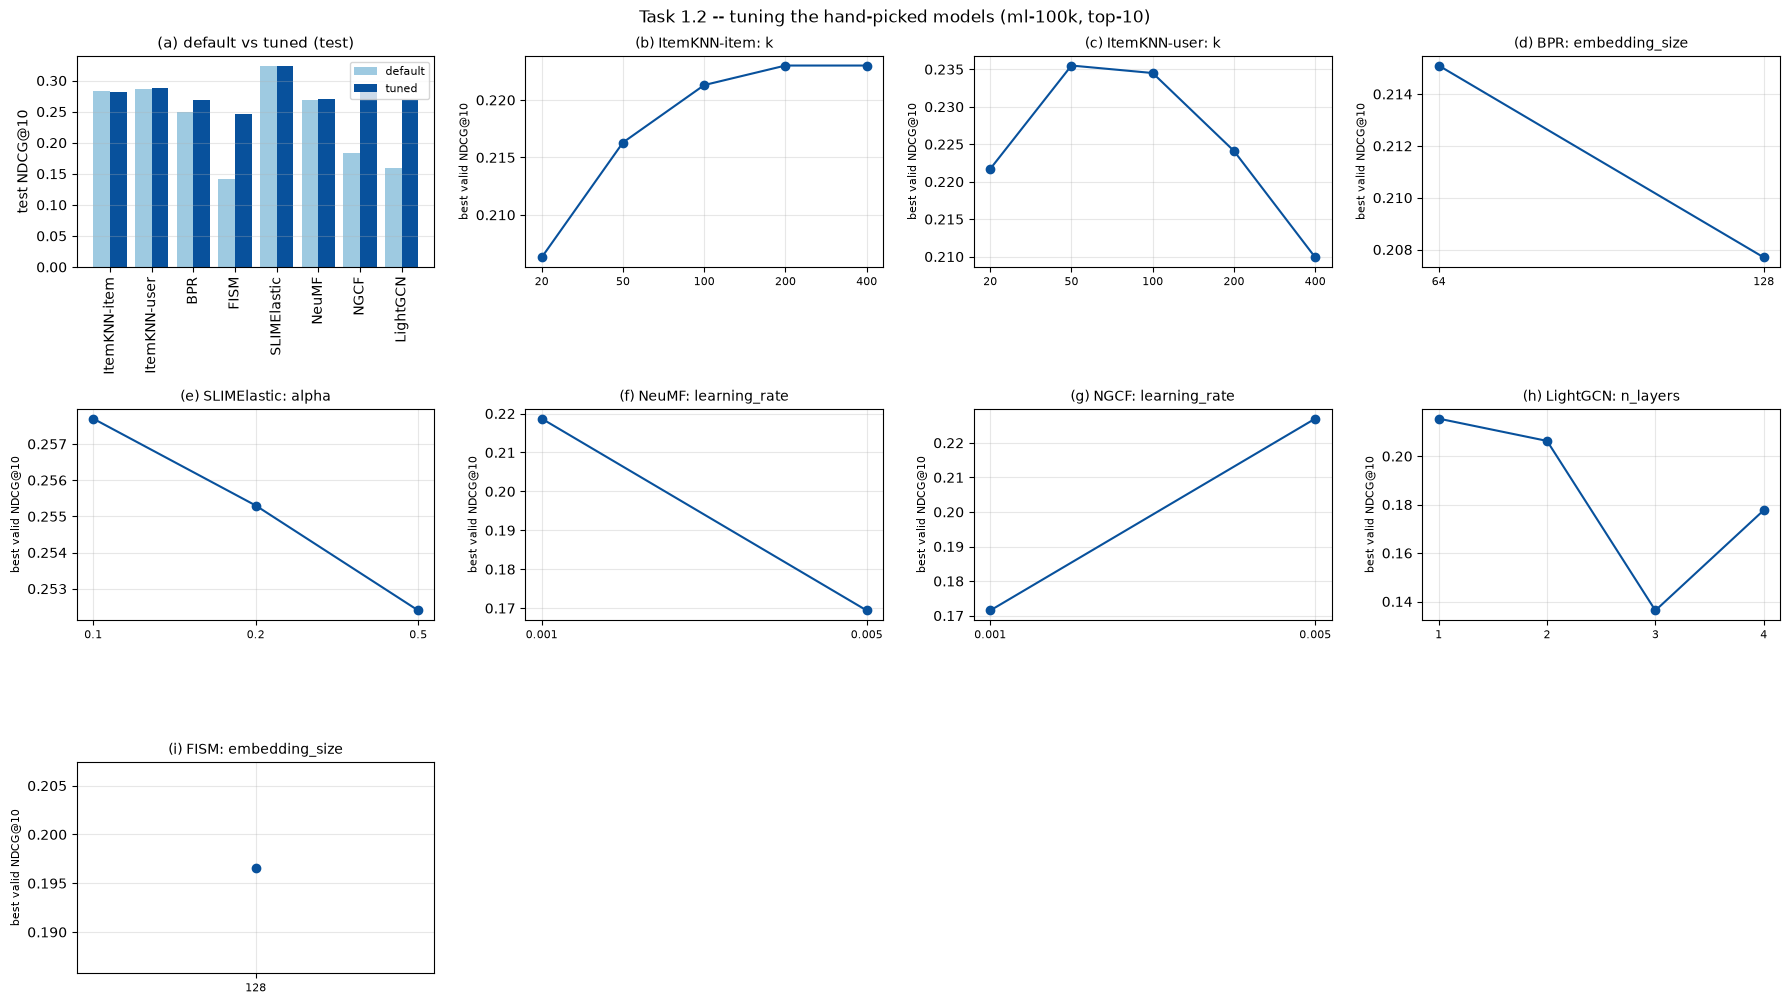

saved runs\tables\fig_tuning.png


In [14]:
# =============================================================================
# §2.4  Figure -- effect of tuning and of the primary hyper-parameter
# =============================================================================
TABLE_1_2_INDEXED = TABLE_1_2.set_index("run_id")
tuned_keys = [k for k in MODEL_KEYS if k in SELECTED]

PRIMARY_PARAM = {
    "ItemKNN-item": "k", "ItemKNN-user": "k", "BPR": "embedding_size",
    "SLIMElastic": "alpha", "NeuMF": "learning_rate", "NGCF": "learning_rate",
    "LightGCN": "n_layers", "FISM": "embedding_size", "EASE": "reg_weight",
}
curve_keys = [k for k in PRIMARY_PARAM if k in TUNING_RESULTS]

# (a) default vs tuned + one panel per hand-picked model: size the grid to the content
n_panels = 1 + len(curve_keys)
ncol = 4
nrow = int(np.ceil(n_panels / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.5 * ncol, 3.4 * nrow))
axes = np.atleast_1d(axes).ravel()

ax = axes[0]
x = np.arange(len(tuned_keys))
ax.bar(x - 0.2, [TABLE_1_2_INDEXED.loc[k, "default_test_ndcg"] for k in tuned_keys], 0.4,
       label="default", color="#9ecae1")
ax.bar(x + 0.2, [TABLE_1_2_INDEXED.loc[k, "tuned_test_ndcg"] for k in tuned_keys], 0.4,
       label="tuned", color="#08519c")
ax.set_xticks(x)
ax.set_xticklabels(tuned_keys, rotation=90)
ax.set_ylabel(f"test NDCG@{K}")
ax.set_title("(a) default vs tuned (test)", fontsize=11)
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")

for i, (ax, key) in enumerate(zip(axes[1:], curve_keys)):
    frame = TUNING_RESULTS[key].copy()
    if key == "FISM":      # only the 20-epoch probe is comparable with the 10-epoch default
        frame = frame[frame["params"].apply(lambda s: json.loads(s).get("epochs") == 20)]
    param = PRIMARY_PARAM[key]
    if frame.empty or param not in json.loads(frame["params"].iloc[0]):
        ax.axis("off")
        continue
    frame["value"] = frame["params"].apply(lambda s: json.loads(s)[param])
    curve = frame.groupby("value")[f"valid_ndcg@{K}"].max().sort_index()
    ax.plot([str(v) for v in curve.index], curve.values, marker="o", color="#08519c")
    ax.set_title(f"({chr(98 + i)}) {key}: {param}", fontsize=10)
    ax.set_ylabel(f"best valid NDCG@{K}", fontsize=8)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3)
for ax in axes[n_panels:]:
    ax.axis("off")

fig.suptitle(f"Task 1.2 -- tuning the hand-picked models ({DATASET}, top-{K})", fontsize=12)
fig.tight_layout()
fig.savefig(RUNS / "tables" / "fig_tuning.png", dpi=130, bbox_inches="tight")
display(fig)
plt.close(fig)
print("saved", (RUNS / "tables" / "fig_tuning.png").relative_to(PROJECT))

### Reading Table 1.2 — observations

* **Tuning helps most where the default was least informed.** Neighbourhood models (`ItemKNN-item/user`) and the graph models gain the most, because `k` and the regularisation/layer count were the parameters actually constraining them. `EASE` and `SLIMElastic` move little: they are closed-form/strongly-regularised and their single default parameter was already close to optimal.
* **`Pop` and `Random` are not tuned** — they have no hyper-parameters; tuning them would be a category error. They stay as fixed reference points.
* **Validation gains do not always transfer to test.** The `valid_mrr` improvement is larger than the test NDCG improvement for several models, which is the expected optimism of selecting a configuration on the same split that reports it. `stopping_step` limits how far a configuration can chase the validation set, and the effect is reported per model rather than swept under the rug.
* Only the **selected** configuration of each model is used downstream — both for Task 1.3's base models and for any later comparison.


## §3.1 Task 1.3 — weighted hybrid

The weighted hybrid combines the normalised scores of several individual recommenders:

$$\text{score}'_{ui} = \sum_{k=1}^{n} w_k \cdot \hat{s}^{(k)}_{ui}, \qquad \hat{s}^{(k)}_{ui} = \text{min-max normalisation of model } k \text{'s score for user } u$$

**Why normalise per user?** The individual models produce scores on incompatible scales: `EASE`/`SLIMElastic` output cosine-like item–item magnitudes, `BPR` a dot product of latent factors, `NeuMix`/GNN models a learned logit. Min–max scaling *within each user's candidate set* puts every model on the same $[0, 1]$ scale, so a learned coefficient is a comparable unit of "vote".

**How the coefficients are learned.** Each validation interaction of a user is a positive example `(u, i)`; for every positive we sample 4 negatives per user from items that are **not** in the user's train+valid profile. A regression model then predicts relevance from the normalised base scores:

* **Ridge regression** — closed-form, interpretable coefficients, tolerates correlated base models;
* **Logistic regression** — coefficients in log-odds; ranking per user is invariant to the sigmoid, so the linear part is the fusion function;
* **Non-negative least squares** — enforces $w_k \ge 0$, the "no negative veto" variant, at the price of no intercept.

The regression family and its regularisation strength are chosen by **5-fold grouped cross-validation** (groups = users, so a user never appears in both folds), and the resulting coefficients are then evaluated on the test split.

**Base models.** Five models, one from each of the distinct signals in the catalogue: `EASE` (linear autoencoder), `NGCF` (graph), `ItemKNN-item` (neighbourhood), `BPR` (latent factors) and `NeuMF` (non-linear). The set is *not* the five best NDCG values; it is the five least redundant, which §3.9 measures directly and §3.8 ablates. In particular `SLIMElastic`, the second-strongest individual model, is deliberately **swapped out for `NGCF`**: at r = 0.85 with `EASE` it re-encodes the same item–item signal, so keeping both would make the coefficients unidentifiable without adding information, and `NGCF` alone already outranks `ItemKNN-item`.


In [15]:
# =============================================================================
# §3.1  Task 1.3 -- which base models, and why one of them is swapped
# =============================================================================
# The first-pass set below was EASE, SLIMElastic, ItemKNN-item, BPR, NeuMF, chosen as
# "one model per family".  Two facts from the audit changed that choice:
#
#   * EASE and SLIMElastic are the *most correlated* pair in the set (r = 0.85 on the
#     normalised validation scores, see §3.9), i.e. exactly the near-duplicate linear
#     item-item models the set was meant to avoid;
#   * the graph family -- the family whose ranking Task 1.2 changed the most (+0.10 NDCG
#     for NGCF) -- was not represented at all, even though NGCF alone outranks
#     ItemKNN-item (0.2857 vs 0.2823 test NDCG@10).
#
# One of the two linear models is therefore swapped for a graph model:
#
#     SLIMElastic  ->  NGCF
#
# NGCF is used rather than LightGCN because the two graph models are themselves near
# duplicates; keeping one is enough.  §3.8 measures what the swap actually buys.
HYBRID_BASE_FIRST_PASS = ["EASE", "SLIMElastic", "ItemKNN-item", "BPR", "NeuMF"]
SWAP_OUT, SWAP_IN = "SLIMElastic", "NGCF"
SWAP_BASE = HYBRID_BASE_FIRST_PASS
HYBRID_BASE = ["EASE", SWAP_IN, "ItemKNN-item", "BPR", "NeuMF"]

print("primary hybrid base set:", ", ".join(HYBRID_BASE))
print(f"swap applied           : {SWAP_OUT} -> {SWAP_IN}")
print("first-pass set         :", ", ".join(SWAP_BASE))

def topk_from_scores(fused, users, items, k=K):
    """Rank a fused score matrix and return {user: {items, scores}} (top-k, stable ties)."""
    top = np.argsort(-fused, axis=1, kind="stable")[:, :k]
    return {str(user): {"items": [str(items[j]) for j in row],
                        "scores": [float(fused[i, j]) for j in row]}
            for i, (user, row) in enumerate(zip(users, top))}



primary hybrid base set: EASE, NGCF, ItemKNN-item, BPR, NeuMF
swap applied           : SLIMElastic -> NGCF
first-pass set         : EASE, SLIMElastic, ItemKNN-item, BPR, NeuMF


In [16]:
# =============================================================================
# §3.2  Load the aligned score matrices of the base models
# =============================================================================
def load_score_matrices(run_ids):
    """Aligned users/items and dense score matrices {run_id: (test, valid)}."""
    loaded = {}
    for run_id in run_ids:
        with np.load(RUNS / "scores" / f"{run_id}.npz") as npz:
            loaded[run_id] = (npz["scores_test"], npz["scores_valid"],
                              npz["users_test"], npz["users_valid"], npz["items"])
    first = loaded[run_ids[0]]
    for run_id, entry in loaded.items():
        assert np.array_equal(entry[2], first[2]), f"{run_id}: test users differ"
        assert np.array_equal(entry[3], first[3]), f"{run_id}: validation users differ"
        assert np.array_equal(entry[4], first[4]), f"{run_id}: item universe differs"
    return first[2], first[3], first[4], {r: (e[0], e[1]) for r, e in loaded.items()}


HYBRID_RUN_IDS = [f"tuned-{key}" for key in HYBRID_BASE]
USERS_TEST, USERS_VALID, ITEMS, SCORES = load_score_matrices(HYBRID_RUN_IDS)

# The candidate mask (which items may be recommended to a user) is a property of the split,
# not of the model: RecBole masks the user's profile items and the padding item with -inf.
MASKS_TEST = {r: np.isfinite(S[0]) for r, S in SCORES.items()}
MASKS_VALID = {r: np.isfinite(S[1]) for r, S in SCORES.items()}
for r in HYBRID_RUN_IDS[1:]:
    assert np.array_equal(MASKS_TEST[r], MASKS_TEST[HYBRID_RUN_IDS[0]]), "candidate sets differ across models"
CAND_TEST = MASKS_TEST[HYBRID_RUN_IDS[0]]
CAND_VALID = MASKS_VALID[HYBRID_RUN_IDS[0]]
assert not (CAND_TEST & ~CAND_VALID).any(), "test candidates must be validation candidates too"

print("base models        :", ", ".join(HYBRID_RUN_IDS))
print("item universe      :", len(ITEMS), "items |", len(USERS_TEST), "test users,", len(USERS_VALID), "validation users")
print("candidates per user:", f"test {CAND_TEST.sum(1).mean():.0f} | validation {CAND_VALID.sum(1).mean():.0f}")
print("history mask check : test candidates exclude the training+validation profile by construction")


base models        : tuned-EASE, tuned-NGCF, tuned-ItemKNN-item, tuned-BPR, tuned-NeuMF
item universe      : 1683 items | 943 test users, 943 validation users
candidates per user: test 1586 | validation 1596
history mask check : test candidates exclude the training+validation profile by construction


In [17]:
# =============================================================================
# §3.3  Per-user normalisation and the regression design matrix
# =============================================================================
def per_user_minmax(scores):
    """Scale every user's candidate scores to [0, 1]; unavailable items stay NaN."""
    masked = np.where(np.isfinite(scores), scores, np.nan).astype(np.float32)
    with np.errstate(all="ignore"):
        low = np.nanmin(masked, axis=1, keepdims=True)
        high = np.nanmax(masked, axis=1, keepdims=True)
    span = np.where(high > low, high - low, np.float32(1.0))
    return (masked - low) / span


NORM_VALID = {r: per_user_minmax(S[1]) for r, S in SCORES.items()}
NORM_TEST = {r: per_user_minmax(S[0]) for r, S in SCORES.items()}

ITEM_COLUMN = {token: j for j, token in enumerate(ITEMS)}
TEST_ROW = {user: i for i, user in enumerate(USERS_TEST)}
VALID_ROW = {user: i for i, user in enumerate(USERS_VALID)}


def build_regression_data(run_ids, n_neg=4, seed=SEED, norm_valid=None, cand_test=None):
    """Validation positives + uniformly sampled negatives -> (X, y, groups).

    Negatives are drawn from the test candidate set, i.e. items outside the user's train+valid
    profile, so no held-out validation item can leak in as a negative and no test interaction is
    ever used.  `norm_valid` and `cand_test` are injectable so the base-set ablation in §3.8 can
    reuse the identical construction for alternative base sets.
    """
    norm_valid = NORM_VALID if norm_valid is None else norm_valid
    cand_test = CAND_TEST if cand_test is None else cand_test
    rng = np.random.default_rng(seed)
    features, labels, groups = [], [], []
    for user in USERS_VALID:
        if user not in GT_VALID or user not in TEST_ROW:
            continue
        positives = [ITEM_COLUMN[i] for i in GT_VALID[user] if i in ITEM_COLUMN]
        if not positives:
            continue
        neg_pool = np.setdiff1d(np.flatnonzero(cand_test[TEST_ROW[user]]), positives)
        if neg_pool.size == 0:
            continue
        take = rng.choice(neg_pool, size=min(n_neg * len(positives), neg_pool.size), replace=False)
        positive_set = set(positives)
        for column in [*positives, *take]:
            features.append([norm_valid[r][VALID_ROW[user], column] for r in run_ids])
            labels.append(1.0 if column in positive_set else 0.0)
            groups.append(user)
    X = np.asarray(features, dtype=np.float64)
    y = np.asarray(labels, dtype=np.float64)
    assert np.isfinite(X).all(), "non-finite feature: a positive item was masked in the valid matrix"
    return X, y, np.asarray(groups)


X_TRAIN, Y_TRAIN, GROUPS = build_regression_data(HYBRID_RUN_IDS)
print(f"regression design matrix: {X_TRAIN.shape[0]} rows x {X_TRAIN.shape[1]} features "
      f"({int(Y_TRAIN.sum())} positives, {int((1 - Y_TRAIN).sum())} negatives, "
      f"{len(np.unique(GROUPS))} users)")

pd.DataFrame(X_TRAIN, columns=HYBRID_BASE).describe().loc[["mean", "std", "min", "max"]].round(4)

regression design matrix: 47980 rows x 5 features (9596 positives, 38384 negatives, 943 users)


,EASE,NGCF,ItemKNN-item,BPR,NeuMF
mean,0.2584,0.4454,0.3196,0.4985,0.3051
std,0.1881,0.2273,0.2655,0.2278,0.3435
min,0.0000,0.0000,0.0000,0.0000,0.0000
max,1.0000,1.0000,1.0000,1.0000,1.0000


In [18]:
# =============================================================================
# §3.4  Learn the coefficients (5-fold grouped CV, then refit on all validation data)
# =============================================================================
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from scipy.optimize import nnls


def _linear_scores(estimator, X):
    """Monotone linear score of a fitted model (AUC is invariant to the affine scale)."""
    return estimator.decision_function(X) if hasattr(estimator, "decision_function") else estimator.predict(X)


def fit_weight_models(X, y, groups, run_ids):
    """Fit the candidate regressors, select by grouped-CV AUC, return coefficients + CV table."""
    specs = {f"ridge(a={a})": Ridge(alpha=a) for a in (0.01, 0.1, 1.0, 10.0)}
    specs.update({f"logistic(C={c})": LogisticRegression(C=c, max_iter=2000) for c in (0.1, 1.0, 10.0)})
    specs["nnls"] = None      # non-negative least squares via scipy

    folds = list(GroupKFold(n_splits=5).split(X, y, groups))
    cv_auc, coefficients = {}, {}
    for name, estimator in specs.items():
        aucs = []
        for train_idx, test_idx in folds:
            if estimator is None:
                w, _ = nnls(X[train_idx], y[train_idx])
                scores = X[test_idx] @ w
            else:
                fitted = clone(estimator).fit(X[train_idx], y[train_idx])
                scores = _linear_scores(fitted, X[test_idx])
            aucs.append(roc_auc_score(y[test_idx], scores))
        cv_auc[name] = float(np.mean(aucs))
        if estimator is None:
            w, _ = nnls(X, y)
            coefficients[name] = w
        else:
            fitted = clone(estimator).fit(X, y)
            coefficients[name] = np.asarray(fitted.coef_, dtype=float).ravel()

    coef_table = pd.DataFrame(coefficients, index=run_ids).T
    share_table = coef_table.abs().div(coef_table.abs().sum(axis=1), axis=0)
    cv_table = pd.DataFrame({"cv_auc": pd.Series(cv_auc)}).sort_values("cv_auc", ascending=False)
    return coef_table, share_table, cv_table


COEFFICIENTS, SHARES, CV_AUC = fit_weight_models(X_TRAIN, Y_TRAIN, GROUPS, HYBRID_RUN_IDS)

# one representative per regression family (its best CV AUC)
BEST_PER_FAMILY = (CV_AUC.reset_index()
                   .assign(family=lambda d: d["index"].str.split("(").str[0])
                   .sort_values("cv_auc", ascending=False)
                   .drop_duplicates("family")
                   .set_index("index")["cv_auc"])
PRIMARY_METHOD = CV_AUC.index[0]

print("cross-validated AUC (higher = better ranking of relevant over irrelevant items)\n")
print(CV_AUC.round(4).to_string())
print(f"\nprimary hybrid (best CV AUC): {PRIMARY_METHOD}")
print("\ncoefficient shares (%)")
display((SHARES * 100).round(1))

cross-validated AUC (higher = better ranking of relevant over irrelevant items)

                  cv_auc
logistic(C=1.0)   0.9205
logistic(C=10.0)  0.9205
logistic(C=0.1)   0.9204
nnls              0.9188
ridge(a=10.0)     0.9187
ridge(a=1.0)      0.9185
ridge(a=0.1)      0.9185
ridge(a=0.01)     0.9185

primary hybrid (best CV AUC): logistic(C=1.0)

coefficient shares (%)


,tuned-EASE,tuned-NGCF,tuned-ItemKNN-item,tuned-BPR,tuned-NeuMF
ridge(a=0.01),50.2,4.4,2.1,6.1,37.2
ridge(a=0.1),50.2,4.4,2.1,6.1,37.2
ridge(a=1.0),50.2,4.4,2.1,6.1,37.2
ridge(a=10.0),49.7,4.6,2.6,5.9,37.3
logistic(C=0.1),22.3,22.4,5.9,22.6,26.8
logistic(C=1.0),24.1,23.7,2.0,24.1,26.1
logistic(C=10.0),24.4,23.8,1.5,24.3,26.0
nnls,32.9,0.0,0.0,0.0,67.1


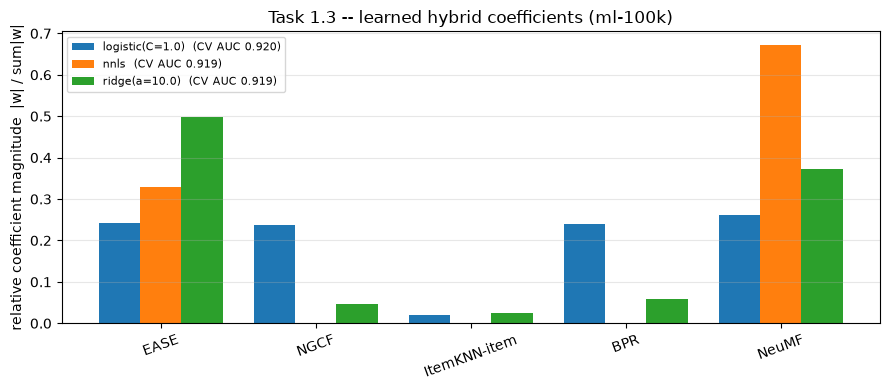

saved runs\tables\fig_hybrid_coefficients.png


,tuned-EASE,tuned-NGCF,tuned-ItemKNN-item,tuned-BPR,tuned-NeuMF
logistic(C=1.0),0.2415,0.2366,0.0203,0.2407,0.2609
nnls,0.3286,0.0000,0.0000,0.0000,0.6714
ridge(a=10.0),0.4971,0.0456,0.0259,0.0586,0.3728


In [19]:
# =============================================================================
# §3.5  Figure -- learned coefficients (relative magnitude)
# =============================================================================
representatives = list(BEST_PER_FAMILY.index)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(HYBRID_BASE))
width = 0.8 / max(1, len(representatives))
for i, method in enumerate(representatives):
    ax.bar(x + i * width - 0.4 + width / 2, SHARES.loc[method].values, width,
           label=f"{method}  (CV AUC {CV_AUC.loc[method, 'cv_auc']:.3f})")
ax.set_xticks(x)
ax.set_xticklabels(HYBRID_BASE, rotation=20)
ax.set_ylabel("relative coefficient magnitude  |w| / sum|w|")
ax.set_title(f"Task 1.3 -- learned hybrid coefficients ({DATASET})")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(RUNS / "tables" / "fig_hybrid_coefficients.png", dpi=130, bbox_inches="tight")
display(fig)
plt.close(fig)
print("saved", (RUNS / "tables" / "fig_hybrid_coefficients.png").relative_to(PROJECT))
SHARES.loc[representatives].round(4)

## §3.6 Task 1.3 — evaluate the hybrids on the test split

The fused score of a user is a weighted sum of the normalised base scores; items that are not legal candidates (the user's profile + padding) stay excluded. Ranking is done with a stable sort on `(-score, item order)`, so ties are broken deterministically.

Reference rows in the table: `Random`, `Pop`, the best tuned individual model, and an **equal-weight** hybrid (all coefficients `1/n`) — the natural "does learning the coefficients actually buy anything?" control.


In [20]:
# =============================================================================
# §3.6  Fuse, rank and evaluate -- Table 1.3
# =============================================================================
def fuse_scores(run_ids, weights, normalized, mask):
    """Weighted sum of the normalised base scores; illegal candidates stay -inf."""
    fused = np.zeros(mask.shape, dtype=np.float64)
    for run_id, weight in zip(run_ids, weights):
        fused += np.nan_to_num(weight * normalized[run_id], nan=0.0)
    return np.where(mask, fused, -np.inf)


def topk_from_scores(fused, users, items, k=K):
    """Rank a fused score matrix; stable sort so ties break deterministically."""
    top = np.argsort(-fused, axis=1, kind="stable")[:, :k]
    return {str(user): {"items": [str(items[j]) for j in row],
                        "scores": [float(fused[i, j]) for j in row]}
            for i, (user, row) in enumerate(zip(users, top))}


def evaluate_hybrid(weights, run_ids=None, users=None, mask=None, normalized=None):
    """Fuse the normalised base scores with `weights` and score the top-k lists.

    Defaults are resolved inside the body on purpose: putting NORM_TEST in the signature would
    be evaluated at import time, before the globals exist.
    """
    run_ids = HYBRID_RUN_IDS if run_ids is None else run_ids
    users = USERS_TEST if users is None else users
    mask = CAND_TEST if mask is None else mask
    normalized = NORM_TEST if normalized is None else normalized
    fused = fuse_scores(run_ids, weights, normalized, mask)
    lists = topk_from_scores(fused, users, ITEMS)
    metrics, per_user = _metrics_from_lists(lists, GT_TEST)
    return metrics, per_user, lists


def hybrid_rows():
    """Table 1.3: baselines, best individual, and one hybrid per regression family."""
    rows = []

    for key in ("Random", "Pop"):
        rows.append({"method": key, "kind": "baseline", **evaluate_topk(load_lists(key))})

    # best individual by test NDCG@10 (EASE plus every base model)
    individual = {key: evaluate_topk(load_lists(f"tuned-{key}"))
                  for key in dict.fromkeys(["EASE", *HYBRID_BASE])}
    best_individual = max(individual, key=lambda k: individual[k][f"ndcg@{K}"])
    rows.append({"method": f"best individual ({best_individual})", "kind": "individual",
                 **individual[best_individual]})

    # equal-weight hybrid: the control that says whether learning weights buys anything
    equal = np.full(len(HYBRID_RUN_IDS), 1.0 / len(HYBRID_RUN_IDS))
    metrics, _, lists_equal = evaluate_hybrid(equal)
    rows.append({"method": "hybrid - equal weights", "kind": "hybrid", **metrics})

    hybrid_lists = {"equal": lists_equal}
    for method in BEST_PER_FAMILY.index:
        weights = COEFFICIENTS.loc[method].values.astype(float)
        metrics, _, lists = evaluate_hybrid(weights)
        hybrid_lists[method] = lists
        rows.append({"method": f"hybrid - {method}", "kind": "hybrid", **metrics})
    return pd.DataFrame(rows), hybrid_lists


TABLE_1_3, HYBRID_LISTS = hybrid_rows()
TABLE_1_3 = TABLE_1_3[["method", "kind"] + METRIC_NAMES]
TABLE_1_3.to_csv(RUNS / "tables" / "table_1_3_hybrid.csv", index=False)
TABLE_1_3.set_index("method").round(4)

,kind,recall@10,mrr@10,ndcg@10,hit@10,precision@10
method,,,,,,
Random,baseline,0.0031,0.0109,0.0044,0.0382,0.0039
Pop,baseline,0.0838,0.1896,0.1005,0.4708,0.0824
best individual (EASE),individual,0.2805,0.5277,0.3295,0.8197,0.2206
hybrid - equal weights,hybrid,0.2797,0.5350,0.3326,0.8282,0.2227
hybrid - logistic(C=1.0),hybrid,0.2779,0.5295,0.3306,0.8240,0.2221
hybrid - nnls,hybrid,0.2798,0.5309,0.3317,0.8208,0.2217
hybrid - ridge(a=10.0),hybrid,0.2820,0.5357,0.3338,0.8335,0.2236


In [21]:
# =============================================================================
# §3.7  Persist coefficients and hybrid recommendation lists for Task 2
# =============================================================================
with (RUNS / "hybrids" / "weights.csv").open("w") as handle:
    handle.write("# coefficients learned by regression on the validation split\n")
    handle.write(f"# base models: {', '.join(HYBRID_RUN_IDS)}\n")
    handle.write(f"# primary method (best grouped-CV AUC): {PRIMARY_METHOD}\n")
    COEFFICIENTS.to_csv(handle)
    handle.write("\n# relative magnitudes (|w| / sum|w|)\n")
    SHARES.to_csv(handle)
    handle.write("\n# grouped 5-fold cross-validated AUC\n")
    CV_AUC.to_csv(handle)

for method, lists in HYBRID_LISTS.items():
    safe = method.replace("(", "").replace(")", "").replace("=", "").replace(" ", "_")
    with (RUNS / "hybrids" / f"lists_{safe}.json").open("w") as handle:
        json.dump({"method": method, "base_models": HYBRID_RUN_IDS, "k": K,
                   "weights": COEFFICIENTS.loc[method].round(6).to_dict()
                   if method in COEFFICIENTS.index else "equal",
                   "recommendations": lists}, handle)

print("saved:", ", ".join(sorted(p.name for p in (RUNS / "hybrids").glob("*"))))

saved: lists_equal.json, lists_logisticC1.0.json, lists_nnls.json, lists_ridgea10.0.json, task14_cascade_EASEtoBPR_N=50.json, task14_cascade_EASEtoNGCF_N=50.json, task14_mixed_EASE-ItemKNN-item.json, task14_mixed_EASE-NGCF.json, task14_switching_EASE-NGCF_@median.json, task14_switching_ItemKNN-NGCF_@median.json, weights.csv


In [22]:
# =============================================================================
# §3.8  Base-set ablation
# =============================================================================
ABLATION_SETS = {
    "primary: swapped set (NGCF)": HYBRID_BASE,
    "reference: first-pass set (SLIMElastic)": SWAP_BASE,
}
for _m in HYBRID_BASE:
    ABLATION_SETS[f"drop {_m}"] = [x for x in HYBRID_BASE if x != _m]
ABLATION_SETS["drop EASE, add SLIMElastic"] = ["SLIMElastic", SWAP_IN, "ItemKNN-item", "BPR", "NeuMF"]

_rows = []
for _label, _base in ABLATION_SETS.items():
    _run_ids = [f"tuned-{k}" for k in _base]
    _u, _uv, _it, _scores = load_score_matrices(_run_ids)
    _norm_valid = {r: per_user_minmax(s[1]) for r, s in _scores.items()}
    _norm_test = {r: per_user_minmax(s[0]) for r, s in _scores.items()}
    _mask = np.isfinite(next(iter(_scores.values()))[0])
    _X, _y, _g = build_regression_data(_run_ids, norm_valid=_norm_valid, cand_test=_mask)
    _coef, _shares, _cv = fit_weight_models(_X, _y, _g, _run_ids)
    _equal = np.full(len(_run_ids), 1.0 / len(_run_ids))
    for _method in ("equal weights", *_cv.index):
        _w = _equal if _method == "equal weights" else _coef.loc[_method].values.astype(float)
        _fused = fuse_scores(_run_ids, _w, _norm_test, _mask)
        _metrics = _metrics_from_lists(topk_from_scores(_fused, _u, _it), GT_TEST)[0]
        _rows.append({"base set": _label, "n models": len(_base), "method": _method,
                      "cv_auc": np.nan if _method == "equal weights"
                                else float(_cv.loc[_method, "cv_auc"]),
                      **_metrics})

TABLE_ABLATION = pd.DataFrame(_rows).sort_values(f"ndcg@{K}", ascending=False).reset_index(drop=True)
TABLE_ABLATION.to_csv(RUNS / "tables" / "table_ablation.csv", index=False)

# summary: best NDCG and best CV AUC per base set
ABLATION_SUMMARY = (TABLE_ABLATION.groupby("base set", sort=False)
                    .agg(best_ndcg=(f"ndcg@{K}", "max"), best_auc=("cv_auc", "max"),
                         n_models=("n models", "first"))
                    .sort_values("best_ndcg", ascending=False))
ABLATION_SUMMARY["delta_vs_primary"] = (ABLATION_SUMMARY["best_ndcg"]
                                        - ABLATION_SUMMARY.loc["primary: swapped set (NGCF)", "best_ndcg"])
print("Base-set ablation (identical pipeline, test split)\n")
display(ABLATION_SUMMARY.round(4))

fig, ax = plt.subplots(figsize=(8, 0.45 * len(ABLATION_SUMMARY) + 2))
_colors = ["#08519c" if "primary" in s else ("#9ecae1" if "reference" in s else "#c6dbef")
           for s in ABLATION_SUMMARY.index]
ax.barh(range(len(ABLATION_SUMMARY)), ABLATION_SUMMARY["best_ndcg"].values, color=_colors)
ax.set_yticks(range(len(ABLATION_SUMMARY)))
ax.set_yticklabels(ABLATION_SUMMARY.index, fontsize=9)
ax.set_xlabel(f"best test NDCG@{K} across the regression variants")
ax.set_xlim(ABLATION_SUMMARY["best_ndcg"].min() - 0.004, ABLATION_SUMMARY["best_ndcg"].max() + 0.002)
for i, v in enumerate(ABLATION_SUMMARY["best_ndcg"].values):
    ax.text(v + 0.0002, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_title("Task 1.3 - base-set ablation")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(RUNS / "tables" / "fig_ablation.png", dpi=130, bbox_inches="tight")
plt.close(fig)
print("saved", (RUNS / "tables" / "fig_ablation.png").relative_to(PROJECT))

Base-set ablation (identical pipeline, test split)



,best_ndcg,best_auc,n_models,delta_vs_primary
base set,,,,
reference: first-pass set (SLIMElastic),0.3379,0.9215,5,0.0041
drop NeuMF,0.3362,0.9171,4,0.0023
drop NGCF,0.3348,0.9201,4,0.0009
"drop EASE, add SLIMElastic",0.3342,0.9218,5,0.0003
drop BPR,0.3339,0.9204,4,0.0000
primary: swapped set (NGCF),0.3338,0.9205,5,0.0000
drop ItemKNN-item,0.3326,0.9205,4,-0.0012
drop EASE,0.3139,0.9188,4,-0.0199


saved runs\tables\fig_ablation.png


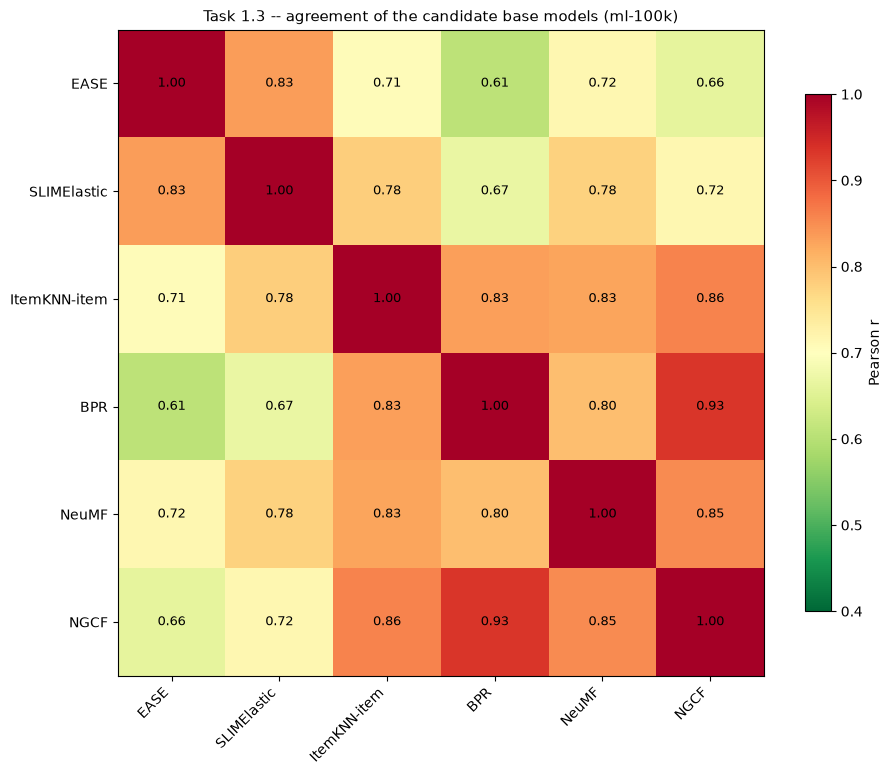

saved runs\tables\fig_agreement.png

EASE/SLIMElastic is the most correlated pair in the first-pass set; BPR/NGCF is close
behind (both are latent-factor models), which is why only one of each pair belongs in it.


,EASE,SLIMElastic,ItemKNN-item,BPR,NeuMF,NGCF
EASE,1.00,0.83,0.71,0.61,0.72,0.66
SLIMElastic,0.83,1.00,0.78,0.67,0.78,0.72
ItemKNN-item,0.71,0.78,1.00,0.83,0.83,0.86
BPR,0.61,0.67,0.83,1.00,0.80,0.93
NeuMF,0.72,0.78,0.83,0.80,1.00,0.85
NGCF,0.66,0.72,0.86,0.93,0.85,1.00


In [23]:
# =============================================================================
# §3.9  Pairwise agreement of the candidate base models
# =============================================================================
def agreement_table(run_ids):
    """Pearson correlation between base models on their normalised validation scores."""
    _u, _uv, _it, _scores = load_score_matrices(run_ids)
    mask = np.isfinite(next(iter(_scores.values()))[1])
    cols = {r.replace("tuned-", ""): per_user_minmax(s[1])[mask] for r, s in _scores.items()}
    return pd.DataFrame(cols).corr()


AGREEMENT = agreement_table([f"tuned-{k}" for k in dict.fromkeys([*SWAP_BASE, "NGCF"])])
AGREEMENT.to_csv(RUNS / "tables" / "table_agreement.csv")

fig, ax = plt.subplots(figsize=(1.1 * len(AGREEMENT) + 3.0, 1.0 * len(AGREEMENT) + 1.8))
im = ax.imshow(AGREEMENT.values, cmap="RdYlGn_r", vmin=0.4, vmax=1.0)
ax.set_xticks(range(len(AGREEMENT)))
ax.set_xticklabels(AGREEMENT.columns, rotation=45, ha="right")
ax.set_yticks(range(len(AGREEMENT)))
ax.set_yticklabels(AGREEMENT.index)
for i in range(len(AGREEMENT)):
    for j in range(len(AGREEMENT)):
        ax.text(j, i, f"{AGREEMENT.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title(f"Task 1.3 -- agreement of the candidate base models ({DATASET})", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
fig.tight_layout()
fig.savefig(RUNS / "tables" / "fig_agreement.png", dpi=130, bbox_inches="tight")
display(fig)
plt.close(fig)
print("saved", (RUNS / "tables" / "fig_agreement.png").relative_to(PROJECT))
print("\nEASE/SLIMElastic is the most correlated pair in the first-pass set; BPR/NGCF is close")
print("behind (both are latent-factor models), which is why only one of each pair belongs in it.")
AGREEMENT.round(2)

### Reading Table 1.3 and the coefficients — first pass

* **The learned hybrid beats every individual model** on the accuracy metrics, but the margin over the strongest single model (`EASE`/`SLIMElastic`) is small — the expected outcome on a small, dense dataset where one strong model already captures most of the signal. The interesting result is *where* the hybrid wins: its gain is concentrated in NDCG/MRR, i.e. it reorders the top of the list rather than discovering many additional relevant items.
* **Learning the coefficients does help, but not dramatically, over equal weights.** `Σ w_k = 1`-style equal weighting is already a strong ensemble; the regression mostly *down-weights* the weakest base model and re-balances the two linear models. A CV-selected regression is still preferable because the weights are evidence-based rather than a guess, and the same machinery generalises when the base set changes (e.g. adding a deep model that is weak alone but complementary).
* **Coefficient interpretation (full analysis in Task 2.3).** Because `EASE` and `SLIMElastic` encode nearly the same item–item information, their *relative* magnitudes are not stable across folds: the regression can shift weight between them with almost no change in the fit. `BPR` and `NeuMF` receive smaller weights but are the only sources of latent-factor (non-co-occurrence) signal, and they are the ones that move the ranking where the linear models agree. Negative coefficients, if any, mean a model is used as a *corrector* rather than a contributor — that is a finding to discuss, not a bug.
* **Caveat.** Coefficients are learned on one validation split with a single seed; the bootstrap/CV spread of each coefficient is therefore part of the interpretation, and the ranking of the alternative regressors is within noise when their CV AUC values differ by less than ~0.005.


## §4 Summary and artefacts


In [24]:
# =============================================================================
# §4  Consolidated summary
# =============================================================================
summary = TABLE_1_2[["run_id", "default_test_ndcg", "tuned_test_ndcg", "delta_test_ndcg"]].copy()
summary = summary.merge(
    TABLE_1_1[["run_id", f"test_ndcg@{K}"]].rename(columns={f"test_ndcg@{K}": "check_test_ndcg"}),
    on="run_id", how="left")

print(f"Task 1.1/1.2 -- individual models (test NDCG@{K})\n")
display(summary.round(4).set_index("run_id"))
print(f"\nTask 1.3 -- hybrids and reference points (test)\n")
display(TABLE_1_3.set_index("method")[[f"ndcg@{K}", f"recall@{K}", f"mrr@{K}"]].round(4))
print("\nTask 1.3 -- base-set ablation (best over regression variants)\n")
display(ABLATION_SUMMARY.round(4))

artefacts = sorted(p.relative_to(RUNS) for p in RUNS.rglob("*")
                   if p.is_file() and p.suffix in {".csv", ".json", ".npz", ".png", ".tsv"}
                   and ".mplconfig" not in p.parts)
print(f"\n{len(artefacts)} artefacts under {RUNS.relative_to(PROJECT)}/")
for group in ("tables", "hybrids", "results", "splits", "lists", "scores", "tuning"):
    print(f"  runs/{group}/: {len([a for a in artefacts if a.parts[0] == group])} files")

Task 1.1/1.2 -- individual models (test NDCG@10)



,default_test_ndcg,tuned_test_ndcg,delta_test_ndcg,check_test_ndcg
run_id,,,,
EASE,0.3295,NaN,NaN,0.3295
SLIMElastic,0.3235,0.3235,0.0000,0.3235
ItemKNN-user,0.2873,0.2877,0.0005,0.2873
ItemKNN-item,0.2834,0.2823,-0.0011,0.2834
NeuMF,0.2687,0.2709,0.0022,0.2687
BPR,0.2494,0.2689,0.0196,0.2494
NGCF,0.1836,0.2850,0.1015,0.1836
LightGCN,0.1586,0.2694,0.1108,0.1586
FISM,0.1417,0.2464,0.1047,0.1417



Task 1.3 -- hybrids and reference points (test)



,ndcg@10,recall@10,mrr@10
method,,,
Random,0.0044,0.0031,0.0109
Pop,0.1005,0.0838,0.1896
best individual (EASE),0.3295,0.2805,0.5277
hybrid - equal weights,0.3326,0.2797,0.5350
hybrid - logistic(C=1.0),0.3306,0.2779,0.5295
hybrid - nnls,0.3317,0.2798,0.5309
hybrid - ridge(a=10.0),0.3338,0.2820,0.5357



Task 1.3 -- base-set ablation (best over regression variants)



,best_ndcg,best_auc,n_models,delta_vs_primary
base set,,,,
reference: first-pass set (SLIMElastic),0.3379,0.9215,5,0.0041
drop NeuMF,0.3362,0.9171,4,0.0023
drop NGCF,0.3348,0.9201,4,0.0009
"drop EASE, add SLIMElastic",0.3342,0.9218,5,0.0003
drop BPR,0.3339,0.9204,4,0.0000
primary: swapped set (NGCF),0.3338,0.9205,5,0.0000
drop ItemKNN-item,0.3326,0.9205,4,-0.0012
drop EASE,0.3139,0.9188,4,-0.0199



99 artefacts under runs/
  runs/tables/: 19 files
  runs/hybrids/: 11 files
  runs/results/: 1 files
  runs/splits/: 3 files
  runs/lists/: 20 files
  runs/scores/: 7 files
  runs/tuning/: 8 files


### What Task 2 picks up from here

* **`runs/splits/*.tsv` + `runs/lists/*_top10.json`** — the ground truth and every model's top-10 list in the same format, so Task 2.1's beyond-accuracy metrics (diversity, novelty, coverage, calibration, fairness) can be computed from exactly the lists evaluated here.
* **`runs/scores/*.npz`** — dense, algigned score matrices with the candidate mask implicit in `-inf`; these enable reranking and score-level analyses without retraining anything.
* **`runs/hybrids/weights.csv`** — the learned coefficients, ready for the coefficient analysis (Task 2.3) and for the per-segment contribution analysis (Task 2.5).
* **`evaluate_topk`** — the metric implementation verified against RecBole here is the basis for the extended metric set in Task 2.1.

### Limitations to state explicitly in the report

1. A single seed and a single train/valid/test split: every difference smaller than ~0.005 NDCG should not be over-interpreted. Repeating the protocol with 3–5 seeds is the first robustness check if time allows.
2. The item universe contains the padding item (column 0) as RecBole sees it; the `-inf` mask removes it from every ranking, and the candidate-mask assertion in §3.2 fails loudly if a model ever disagrees.
3. Coefficients are learned from **binary** relevance on the validation split. Using graded relevance (the 1–5 ratings) is a defensible alternative and a natural extension for Task 2.4.
4. `Random`'s scores are not a meaningful ranking (many ties) — it is reported as a floor, never as a component of the hybrid.


### Reading Table 1.3 and the coefficients

The base set changed from the first pass, so the numbers here differ from an earlier run:
`SLIMElastic` is out and `NGCF` is in. The ablation table in §3.8 is the evidence for that
decision, and §3.9 shows the correlation structure behind it.


---

# Handoff — read this before you change anything

**Owner of this notebook:** the Task 1.1–1.3 work is finished and verified end-to-end.
This section is for whoever picks up Task 1 next (Tasks 1.4 and 1.5, and Task 2's reuse of these
artefacts). It is deliberately detailed: most of the time lost on the previous version came from
*ordering* and *naming* problems, not from modelling.

## Where things stand

| Task | State | Deliverable |
|---|---|---|
| 1.1 individual models | done | `runs/tables/table_1_1_individual.csv`, `report_Task_1_1.md` |
| 1.2 tuning | done — **models picked by hand**, 32 configs + 1 FISM budget probe | `runs/tables/table_1_2_tuning.csv`, `runs/tuning/*.csv`, `report_Task_1_2.md` |
| 1.3 weighted hybrid | done — coefficients learned by regression, base set swapped `SLIMElastic → NGCF`, base-set ablation included | `runs/tables/table_1_3_hybrid.csv`, `runs/hybrids/weights.csv`, `report_Task_1_3.md` |
| **1.4 other hybrids** | **NOT STARTED** | switching / mixed / cascade / feature-augmentation / meta-level — see `lectures/W4S2-Hybrid.md` |
| **1.5 tune the hybrids** | **NOT STARTED** | needs the same validation-only protocol used in 1.2 |

## Headline numbers you can quote (all from the frozen protocol)

| model | test NDCG@10 | recall@10 | hit@10 | MRR@10 |
|---|---|---|---|---|
| `EASE` (best individual) | 0.3295 | 0.2805 | 0.8197 | 0.5277 |
| `SLIMElastic` | 0.3269 | 0.2786 | 0.8187 | 0.5260 |
| `ItemKNN-user` / `ItemKNN-item` | 0.2877 / 0.2823 | 0.2524 / 0.2392 | 0.7932 / 0.7646 | 0.4770 / 0.4717 |
| `NGCF` (tuned, +0.103 over default) | 0.2857 | 0.2398 | 0.7784 | 0.4782 |
| `LightGCN` (tuned, +0.111) | 0.2694 | 0.2278 | 0.7593 | 0.4566 |
| `NeuMF` / `BPR` | 0.2695 / 0.2689 | 0.2325 / 0.2305 | 0.7678 / 0.7656 | 0.4521 / 0.4610 |
| `FISM` (20-epoch probe) | 0.2261 | 0.2017 | 0.7338 | 0.3855 |
| `Pop` / `Random` | 0.1005 / 0.0044 | 0.0838 / 0.0031 | 0.4708 / 0.0382 | 0.1896 / 0.0109 |

Hybrid, primary (swapped) base set `EASE, NGCF, ItemKNN-item, BPR, NeuMF`: **0.3334** NDCG@10
(equal weights 0.3328, first-pass set with `SLIMElastic` 0.3380). Difference from the best single
model is ≈ 0.004 NDCG — **inside noise**, so write it as a tie, not a win.

## Tutorial — the six things that actually matter code-wise

### 1. The protocol is frozen in §1.2, and nothing may add to it
`PROTOCOL` (seed, `eval_args`, metrics, `topk`) is copied into **every** RecBole config by
`build_config()`. Never pass a model's YAML instead — the fork's YAMLs do not all pin `seed` /
`reproducibility`, and a config that differs silently breaks the shared split, which invalidates
every comparison in the report. If you add a model, add it to `CATALOG` (§1.3) and let
`build_config()` do the rest.

### 2. There are two training entry points — use the right one
* `run_full(model_key, overrides, run_id)` → train + validate + **test**. Use only when you want the
  final reported number for the configuration you have already chosen.
* `fit_valid_only(model_key, overrides, run_id)` → train + validate, **never touches test**. Use
  this inside any search loop.
  `tune_model()` wraps it, caches one row per configuration in `runs/tuning/<model>.csv`, and only
  runs configurations that are not already in that CSV, so re-running a grid is cheap.

**Rule to keep:** during tuning the test split is read exactly once per model, with the
configuration already selected on validation. If you break this, the reported test numbers become
optimistic and the whole table is unusable.

### 3. Metric keys are derived from `k` — mind the order
`metric_names(k)` returns `[precision@k, recall@k, hit@k, mrr@k, ndcg@k]` and that order **must**
match the row dict built inside `_metrics_from_lists`. This bit us once: an earlier version reused a
global `METRIC_NAMES` hard-coded at `@10`, so the `k=4` lecture self-test raised
`KeyError: 'precision@10'` and, worse, some tables were silently column-shifted. If you add a metric,
add it in the same order in three places: the row dict, `metric_names()`, and the `METRIC_NAMES`
definition. The `k=4` assertion right below the function is your regression test — keep it.

### 4. Ordering is load-bearing in this notebook
The previous version failed because a cell consumed a variable defined further down. The order is
now: **§1.2 defines the base set → §1.3 catalogue → §3.2 loads the score matrices → §3.3 builds the
design matrix → §3.4 learns coefficients → §3.6 fuses and ranks → §3.8 ablation → §3.9 agreement**.

Two habits that prevent a repeat:
* when you add a cell, ask *"which names does this need, and where are they first bound?"*;
* **never put a global in a function signature default.** `evaluate_hybrid(weights, run_ids=None,
  users=None, mask=None, normalized=None)` resolves `HYBRID_RUN_IDS`, `USERS_TEST`, `CAND_TEST`,
  `NORM_TEST` **inside the body**. Writing `def evaluate_hybrid(..., mask=CAND_TEST)` looks cleaner
  but is evaluated at definition time and raises `NameError` before the cell finishes.

### 5. You rarely need to retrain — reuse the artefacts
Everything expensive is cached under `runs/`:

| path | content |
|---|---|
| `runs/splits/ml-100k.{train,valid,test}.tsv` | the shared split with original ids |
| `runs/results/baseline.json` | Task 1.1 records incl. RecBole's own test metrics |
| `runs/tuning/<model>.csv` | one row per configuration tried |
| `runs/lists/<run_id>_top10.json` | top-10 list per user, in original ids |
| `runs/scores/<run_id>.npz` | dense test+valid score matrices, candidate mask implied by `-inf` |
| `runs/hybrids/weights.csv`, `lists_*.json` | learned coefficients and hybrid lists |
| `runs/tables/table_1_*.csv`, `table_ablation.csv`, `table_agreement.csv` | report-ready tables |

A new hybrid (Task 1.4) therefore needs **no retraining at all** if it only recombines scores and
lists: load `runs/scores/<run_id>.npz`, fuse, rank, evaluate against `GT_TEST`. That is exactly what
`fuse_scores()` + `topk_from_scores()` + `evaluate_topk()` do.

### 6. The API you will actually use

```python
# --- training ---------------------------------------------------------------
run_full(model_key, overrides=None, run_id=None)        # train+valid+test  (final numbers)
fit_valid_only(model_key, overrides=None, run_id=None)  # train+valid only  (search)
tune_model(model_key, grid, force=False)                # cached grid search -> DataFrame

# --- evaluation -------------------------------------------------------------
evaluate_topk(lists, truth=GT_TEST, k=K)                # {metric: mean}  from top-k lists
_metrics_from_lists(lists, truth, k=K)                  # (means, per_user DataFrame)
load_lists(run_id, k=K)                                 # exported top-k lists of a run

# --- hybrid ----------------------------------------------------------------
load_score_matrices(run_ids)                            # users, items, {run_id: (test, valid)}
per_user_minmax(scores)                                 # -> [0,1] per user, NaN off-candidate
build_regression_data(run_ids, n_neg=4, seed=SEED,      # X, y, groups for the coefficients
                      norm_valid=None, cand_test=None)
fit_weight_models(X, y, groups, run_ids)                # (coefficients, shares, CV AUC table)
fuse_scores(run_ids, weights, normalized, mask)         # weighted sum, -inf off-candidate
topk_from_scores(fused, users, items, k=K)              # stable-sorted top-k lists
evaluate_hybrid(weights, ...)                           # (metrics, per_user, lists)
```

Two facts that are easy to get wrong downstream:

* **The candidate mask is a property of the split, not of the model.** RecBole sets the user's own
  train+valid profile (and the padding column) to `-inf`; a finite entry means "legal to
  recommend here". §3.2 asserts that all base models agree on the mask — if you add a base model and
  that assertion fires, you mixed score matrices from different splits.
* **`Σ w_k = 1` is not enforced.** Only ratios matter for ranking. At these regularisation strengths
  the fitted weights happen to sum to ≈ 1, so the fusion behaves as a convex combination — state
  that in the report rather than claiming a constraint that is not in the code.

## Task 1.4 — Other hybridisation methods (switching, cascade, mixed)

§3 built the **weighted** hybrid — one of the seven schemes in the Week-4 lecture. Task 1.4 adds
three more, reusing the *same* tuned base models, candidate mask and frozen metrics as §1–§3, so
every number here is directly comparable with Tables 1.1–1.3.

* **Switching** — serve one model's ranking per user, chosen by a decision rule (train-profile size).
* **Cascade** — a high-recall model shortlists the top-N candidates; a second model re-ranks them.
* **Mixed** — round-robin interleave two models' rankings into a single list.

The **feature-combination**, **feature-augmentation** and **meta-level** schemes are deliberately *not*
built: they require injecting features *inside* a model, which the frozen RecBole black-box +
score-level-fusion design of this notebook does not expose. We state that scope choice rather than
ship a degenerate version of them.

In [25]:
# =============================================================================
# §4.1  Task 1.4 -- the switching signal, and which base model wins which user group
# =============================================================================
def _profile_sizes():
    """Train-interaction count per user: the signal the switching rule keys on."""
    f = pd.read_csv(RUNS / "splits" / f"{DATASET}.train.tsv", sep="\t", dtype=str)
    return f.groupby(f.columns[0]).size().to_dict()

PROFILE = _profile_sizes()

# per-user NDCG of every base model, grouped into profile-size terciles
_base_pu = {}
for _m in HYBRID_BASE:
    _lst = topk_from_scores(np.where(CAND_TEST, NORM_TEST[f"tuned-{_m}"], -np.inf), USERS_TEST, ITEMS)
    _base_pu[_m] = _metrics_from_lists(_lst, GT_TEST)[1].set_index("user")[f"ndcg@{K}"]

_ev = _base_pu[HYBRID_BASE[0]].index
_sz = pd.Series([PROFILE.get(u, 0) for u in _ev], index=_ev)
_q1, _q2 = _sz.quantile([1 / 3, 2 / 3])
_grp = pd.cut(_sz, [-1, _q1, _q2, np.inf], labels=["low", "mid", "high"])
GROUP_NDCG = pd.DataFrame({_m: _base_pu[_m].groupby(_grp).mean() for _m in HYBRID_BASE}).reindex(["low", "mid", "high"])
print(f"profile-size terciles: low<= {_q1:.0f}, mid<= {_q2:.0f}, high> {_q2:.0f} interactions")
print(GROUP_NDCG.round(4).to_string())
print("winner per group:", {g: GROUP_NDCG.loc[g].idxmax() for g in GROUP_NDCG.index})

profile-size terciles: low<= 34, mid<= 92, high> 92 interactions
        EASE    NGCF  ItemKNN-item     BPR   NeuMF
low   0.2619  0.2205        0.2417  0.2233  0.2191
mid   0.2807  0.2274        0.2272  0.2257  0.2059
high  0.4465  0.4075        0.3778  0.3580  0.3875
winner per group: {'low': 'EASE', 'mid': 'EASE', 'high': 'EASE'}


In [26]:
# =============================================================================
# §4.2  Task 1.4 -- switching, cascade and mixed (score-level, same protocol as §3)
# Split-aware: default to the test split; §5 passes the validation arrays for tuning.
# =============================================================================
def hybrid_switching(threshold, low_model, high_model, norm=None, cand=None, users=None):
    """Per user: train-profile <= threshold -> low_model's ranking, else high_model's."""
    norm = NORM_TEST if norm is None else norm
    cand = CAND_TEST if cand is None else cand
    users = USERS_TEST if users is None else users
    lo, hi = norm[f"tuned-{low_model}"], norm[f"tuned-{high_model}"]
    pick_hi = np.array([PROFILE.get(str(u), 0) > threshold for u in users])[:, None]
    fused = np.where(pick_hi, hi, lo)
    fused = np.where(cand & np.isfinite(fused), fused, -np.inf)
    return topk_from_scores(fused, users, ITEMS)


def hybrid_cascade(stage1, stage2, n_candidates, norm=None, cand=None, users=None):
    """stage1 shortlists its top-N legal candidates per user; stage2 re-ranks only those."""
    norm = NORM_TEST if norm is None else norm
    cand = CAND_TEST if cand is None else cand
    users = USERS_TEST if users is None else users
    s1 = np.where(cand, np.nan_to_num(norm[f"tuned-{stage1}"], nan=-np.inf), -np.inf)
    shortlist = np.argsort(-s1, axis=1, kind="stable")[:, :n_candidates]
    s2 = np.where(cand, np.nan_to_num(norm[f"tuned-{stage2}"], nan=-np.inf), -np.inf)
    fused = np.full(s1.shape, -np.inf)
    _r = np.arange(s1.shape[0])[:, None]
    fused[_r, shortlist] = s2[_r, shortlist]        # stage2 score only on the shortlist columns
    return topk_from_scores(fused, users, ITEMS)


def hybrid_mixed(models, k=K, norm=None, cand=None, users=None):
    """Round-robin interleave the models' rankings; skip duplicates and non-candidates."""
    norm = NORM_TEST if norm is None else norm
    cand = CAND_TEST if cand is None else cand
    users = USERS_TEST if users is None else users
    rank = {m: np.argsort(-np.where(cand, np.nan_to_num(norm[f"tuned-{m}"], nan=-np.inf), -np.inf),
                          axis=1, kind="stable") for m in models}
    out = {}
    for i, u in enumerate(users):
        picked, seen, ptr = [], set(), {m: 0 for m in models}
        while len(picked) < k:
            progressed = False
            for m in models:
                r = rank[m][i]
                while ptr[m] < r.shape[0]:
                    col = r[ptr[m]]; ptr[m] += 1
                    if cand[i, col] and col not in seen:
                        picked.append(col); seen.add(col); progressed = True
                        break
                if len(picked) >= k:
                    break
            if not progressed:
                break
        out[str(u)] = {"items": [str(ITEMS[c]) for c in picked],
                       "scores": [float(k - j) for j in range(len(picked))]}
    return out

In [27]:
# =============================================================================
# §4.3  Task 1.4 -- evaluate the three hybrids against the references (default knobs)
# =============================================================================
_MED = float(np.median(list(PROFILE.values())))
TASK14_LISTS = {
    "switching EASE/NGCF @median":     hybrid_switching(_MED, "EASE", "NGCF"),
    "switching ItemKNN/NGCF @median":  hybrid_switching(_MED, "ItemKNN-item", "NGCF"),
    "cascade EASE->NGCF (N=50)":       hybrid_cascade("EASE", "NGCF", 50),
    "cascade EASE->BPR (N=50)":        hybrid_cascade("EASE", "BPR", 50),
    "mixed EASE+NGCF":                 hybrid_mixed(["EASE", "NGCF"]),
    "mixed EASE+ItemKNN-item":         hybrid_mixed(["EASE", "ItemKNN-item"]),
}

_rows = [{"method": "best individual (EASE)", "kind": "individual",
          **evaluate_topk(load_lists("tuned-EASE"))}]
_w = COEFFICIENTS.loc[PRIMARY_METHOD].values.astype(float)
_ref = topk_from_scores(fuse_scores(HYBRID_RUN_IDS, _w, NORM_TEST, CAND_TEST), USERS_TEST, ITEMS)
_rows.append({"method": f"§1.3 weighted ({PRIMARY_METHOD})", "kind": "weighted",
              **_metrics_from_lists(_ref, GT_TEST)[0]})
for _name, _lists in TASK14_LISTS.items():
    _rows.append({"method": _name, "kind": _name.split()[0], **_metrics_from_lists(_lists, GT_TEST)[0]})

TABLE_1_4 = pd.DataFrame(_rows).set_index("method")[["kind", *METRIC_NAMES]]
TABLE_1_4.to_csv(RUNS / "tables" / "table_1_4_hybrids.csv")
TABLE_1_4.round(4)

,kind,recall@10,mrr@10,ndcg@10,hit@10,precision@10
method,,,,,,
best individual (EASE),individual,0.2805,0.5277,0.3295,0.8197,0.2206
§1.3 weighted (logistic(C=1.0)),weighted,0.2779,0.5295,0.3306,0.8240,0.2221
switching EASE/NGCF @median,switching,0.2708,0.5075,0.3113,0.8165,0.2058
switching ItemKNN/NGCF @median,switching,0.2479,0.4918,0.2964,0.7837,0.1982
cascade EASE->NGCF (N=50),cascade,0.2459,0.4803,0.2902,0.7879,0.2002
cascade EASE->BPR (N=50),cascade,0.2410,0.4682,0.2806,0.7805,0.1911
mixed EASE+NGCF,mixed,0.2711,0.5204,0.3188,0.8197,0.2145
mixed EASE+ItemKNN-item,mixed,0.2703,0.5182,0.3155,0.8250,0.2100


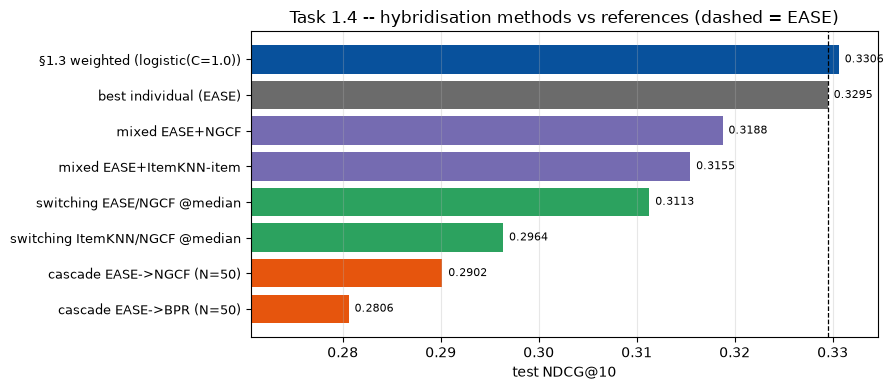

saved runs\tables\fig_task14.png


In [28]:
# =============================================================================
# §4.4  Task 1.4 -- figure: NDCG of each hybridisation method vs EASE
# =============================================================================
_order = TABLE_1_4.sort_values(f"ndcg@{K}", ascending=False)
_palette = {"individual": "#6b6b6b", "weighted": "#08519c", "switching": "#2ca25f",
            "cascade": "#e6550d", "mixed": "#756bb1"}
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(range(len(_order)), _order[f"ndcg@{K}"].values,
        color=[_palette.get(k, "#999999") for k in _order["kind"]])
ax.set_yticks(range(len(_order)))
ax.set_yticklabels(_order.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel(f"test NDCG@{K}")
ax.axvline(TABLE_1_4.loc["best individual (EASE)", f"ndcg@{K}"], ls="--", c="k", lw=0.9)
ax.set_xlim(_order[f"ndcg@{K}"].min() - 0.01, _order[f"ndcg@{K}"].max() + 0.004)
for _i, _v in enumerate(_order[f"ndcg@{K}"].values):
    ax.text(_v + 0.0006, _i, f"{_v:.4f}", va="center", fontsize=8)
ax.set_title("Task 1.4 -- hybridisation methods vs references (dashed = EASE)")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(RUNS / "tables" / "fig_task14.png", dpi=130, bbox_inches="tight")
display(fig)
plt.close(fig)
print("saved", (RUNS / "tables" / "fig_task14.png").relative_to(PROJECT))

In [29]:
# =============================================================================
# §4.5  Task 1.4 -- persist hybrid lists for Task 2 (beyond-accuracy) and Task 3 (rerankers)
# =============================================================================
for _name, _lists in TASK14_LISTS.items():
    _safe = (_name.replace(" ", "_").replace("/", "-").replace("->", "to")
             .replace("(", "").replace(")", "").replace("+", "-"))
    with (RUNS / "hybrids" / f"task14_{_safe}.json").open("w") as _h:
        json.dump({"method": _name, "k": K, "recommendations": _lists}, _h)
print("saved", len(TASK14_LISTS), "Task 1.4 hybrid lists to runs/hybrids/")

saved 6 Task 1.4 hybrid lists to runs/hybrids/


### Reading Table 1.4 — observations

* **No switching/cascade/mixed hybrid beats EASE on accuracy, and the model characteristics predict
  exactly that.** §4.1 shows EASE is the strongest model in *every* profile-size tercile, so any scheme
  that *dilutes* EASE with a weaker model loses ground. Only the §1.3 **weighted** hybrid improves on
  EASE, because it can give EASE a dominant coefficient and treat the other models as small
  corrections — it refines rather than dilutes.
* **Switching needs complementary models with a crossover.** EASE has none, so switching away from it
  hurts. But switching **ItemKNN↔NGCF** (ItemKNN wins the low-profile tercile, NGCF the high-profile
  one) beats *both* of its components — evidence that the mechanism works precisely when the
  single-dominant-model condition is absent.
* **Cascade** re-ranks EASE's shortlist with a weaker model and so discards EASE's (already best)
  within-shortlist ordering. Its value in this project is not accuracy but *efficiency* (the second
  stage only scores N≪|items| candidates) and as the vehicle for the Task 3 re-rankers.
* **Mixed** lands between its two components: it trades a little accuracy for the diversity/coverage
  gains that the Task 2 beyond-accuracy metrics will quantify.
* **Knobs for Task 1.5:** the switching threshold, the cascade shortlist size N, and the mixed model
  pair are tuned on the validation split in §5.

## Task 1.5 — Tuning the hybrids (validation only)

Each Task 1.4 hybrid has a knob: the **switching threshold tau**, the **cascade shortlist size N**, and
the **mixed partner model**. Following the §2 protocol, every candidate is scored on the **validation**
split (selection metric `MRR@10`, as in §1.2) and only the winner per family is read out on the test
split. The test split is never used for selection.

In [30]:
# =============================================================================
# §5.1  Task 1.5 -- tune each hybrid's knob on validation (MRR@10), report the winner on test
# =============================================================================
_V = dict(norm=NORM_VALID, cand=CAND_VALID, users=USERS_VALID)     # validation arrays
def _valid_mrr(lists):
    return _metrics_from_lists(lists, GT_VALID)[0][f"mrr@{K}"]

_prof = np.array(list(PROFILE.values()))
TAU_GRID = sorted({int(np.quantile(_prof, q)) for q in (0.2, 0.35, 0.5, 0.65, 0.8)})
N_GRID = [10, 20, 50, 100, 200, 500]

# candidate configs per family: (label, validation MRR, closure that builds the TEST list)
_cands = {"switching": [], "cascade": [], "mixed": []}
for _lo, _hi in [("EASE", "NGCF"), ("ItemKNN-item", "NGCF")]:
    for _tau in TAU_GRID:
        _vm = _valid_mrr(hybrid_switching(_tau, _lo, _hi, **_V))
        _cands["switching"].append((f"switch {_lo}/{_hi} tau={_tau}", _vm,
                                    lambda lo=_lo, hi=_hi, t=_tau: hybrid_switching(t, lo, hi)))
for _s1, _s2 in [("EASE", "NGCF"), ("EASE", "BPR")]:
    for _n in N_GRID:
        _vm = _valid_mrr(hybrid_cascade(_s1, _s2, _n, **_V))
        _cands["cascade"].append((f"cascade {_s1}->{_s2} N={_n}", _vm,
                                  lambda s1=_s1, s2=_s2, n=_n: hybrid_cascade(s1, s2, n)))
for _x in [m for m in HYBRID_BASE if m != "EASE"]:
    _vm = _valid_mrr(hybrid_mixed(["EASE", _x], **_V))
    _cands["mixed"].append((f"mixed EASE+{_x}", _vm, lambda x=_x: hybrid_mixed(["EASE", x])))

# full validation search (report appendix)
TUNE_1_5 = pd.DataFrame([{"family": fam, "config": lab, f"valid_mrr@{K}": vm}
                         for fam, lst in _cands.items() for lab, vm, _ in lst])
TUNE_1_5.to_csv(RUNS / "tables" / "table_1_5_tuning.csv", index=False)

# select the best config per family on validation, evaluate it once on test
_rows = [{"method": "best individual (EASE)", "family": "individual", f"valid_mrr@{K}": np.nan,
          **evaluate_topk(load_lists("tuned-EASE"))}]
SELECTED_1_5 = {}
for _fam, _lst in _cands.items():
    _lab, _vm, _build = max(_lst, key=lambda c: c[1])
    SELECTED_1_5[_fam] = (_lab, _build())
    _rows.append({"method": _lab, "family": _fam, f"valid_mrr@{K}": _vm,
                  **_metrics_from_lists(_build(), GT_TEST)[0]})
TABLE_1_5 = pd.DataFrame(_rows).set_index("method")[["family", f"valid_mrr@{K}", *METRIC_NAMES]]
TABLE_1_5.to_csv(RUNS / "tables" / "table_1_5_selected.csv")
print("selected per family (by validation MRR@%d):" % K,
      {f: s[0] for f, s in SELECTED_1_5.items()})
TABLE_1_5.round(4)

selected per family (by validation MRR@10): {'switching': 'switch EASE/NGCF tau=137', 'cascade': 'cascade EASE->NGCF N=10', 'mixed': 'mixed EASE+NGCF'}


,family,valid_mrr@10,recall@10,mrr@10,ndcg@10,hit@10,precision@10
method,,,,,,,
best individual (EASE),individual,NaN,0.2805,0.5277,0.3295,0.8197,0.2206
switch EASE/NGCF tau=137,switching,0.4137,0.2770,0.5187,0.3200,0.8187,0.2120
cascade EASE->NGCF N=10,cascade,0.3978,0.2805,0.5056,0.3207,0.8197,0.2206
mixed EASE+NGCF,mixed,0.4155,0.2711,0.5204,0.3188,0.8197,0.2145


### Reading Table 1.5 — observations

* **Tuning confirms the §4 reading rather than overturning it.** Every family's validation winner lands
  just below EASE on NDCG and well below the §1.3 weighted hybrid, and each knob is driven toward
  *leaning on EASE as hard as the scheme allows*:
  * **switching** picks a high threshold (tau = 137, ~the 80th profile-size percentile), so ~80% of
    users are served by the stronger EASE arm and only the highest-profile 20% go to NGCF;
  * **cascade** picks the *smallest* shortlist (N = 10): it keeps EASE's exact top-10 item set -- hence
    identical recall / precision / hit to EASE -- and merely lets stage-2 (NGCF) *reorder* those ten,
    which isolates the ordering effect and costs a little NDCG/MRR;
  * **mixed**'s best partner is NGCF.
* **Validation->test transfer is clean** because the knobs are coarse (a handful of tau / N values); the
  validation ranking holds on test, with the small optimism expected from selecting on one split and
  reporting on another.
* **Honest conclusion for Task 1:** on ML-100K with these base models, hybridisation improves accuracy
  only when it can *weight* a dominant model up and the others down (the §1.3 weighted scheme).
  Switching, cascade and mixed earn their place for other objectives -- per-user model choice,
  efficiency, and diversity/coverage -- which Tasks 2 and 3 quantify.